# 🎧 Spotify Şarkı Analizi: Türler, Duygular ve Makine Öğrenmesi

**Veri:** [TidyTuesday — Spotify Songs](https://github.com/rfordatascience/tidytuesday/tree/master/data/2020/2020-01-21) · ~32 bin şarkı, 6 tür, 24 alt tür

Spotify her şarkı için *dans edilebilirlik*, *enerji*, *pozitiflik (valence)*, *akustiklik* gibi ses özellikleri hesaplıyor. Bu notebook'ta bu sayılarla müziğin "şifresini" çözmeye çalışıyoruz: keşifsel analizden istatistiksel testlere, boyut indirgemeden açıklanabilir makine öğrenmesine ve ölçülebilir bir öneri sistemine kadar.

### İçindekiler
1. Kurulum ve veri
2. Temizlik
3. Türlerin ses imzası
4. İstatistiksel testler — türler gerçekten farklı mı?
5. Duygu haritası — mutlu, gergin, hüzünlü, sakin
6. Zaman içinde müzik — kısalan, yükselen, hüzünlenen şarkılar
7. t-SNE ile şarkı haritası
8. Popülerlik — ses mi, sanatçı mı?
9. 🤖 Tür tahmini — metin modeli (TF-IDF), stacking, LightGBM + Optuna, ensemble, genelleme testi, SHAP, hata analizi
10. 🎵 Öneri sistemi — benzer şarkılar, isabet ölçümü, ruh haline göre çalma listesi
11. Sonuçlar

> Gerekenler: `pip install pandas numpy matplotlib seaborn scikit-learn scipy lightgbm optuna shap`
> İlk çalıştırmada veri (~7 MB) otomatik indirilir. Tüm notebook 2 çekirdekli bir makinede ~12 dakikada çalışır.

## 1. Kurulum ve veri

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy.stats import kruskal, spearmanr, loguniform, randint, uniform
from sklearn.model_selection import (train_test_split, cross_val_score, cross_val_predict,
                                     StratifiedKFold, KFold, RandomizedSearchCV)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (RandomForestClassifier, HistGradientBoostingClassifier,
                              HistGradientBoostingRegressor, VotingClassifier)
from sklearn.metrics import (accuracy_score, f1_score, top_k_accuracy_score, confusion_matrix,
                             classification_report, r2_score, mean_absolute_error)
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors

warnings.filterwarnings("ignore")
SEED = 42

# Görsel tema — renk-körü dostu sabit palet, her tür her grafikte aynı renkte
TURLER = ["pop", "rap", "rock", "latin", "r&b", "edm"]
RENK = dict(zip(TURLER, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#6250d6"]))
GRI = "#52514e"
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlelocation": "left",
                     "axes.spines.top": False, "axes.spines.right": False, "grid.color": "#e6e5e0"})

URL = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2020/2020-01-21/spotify_songs.csv"
DOSYA = Path("spotify_songs.csv")
if not DOSYA.exists():
    pd.read_csv(URL).to_csv(DOSYA, index=False)
ham = pd.read_csv(DOSYA)
print(f"{ham.shape[0]:,} satır, {ham.shape[1]} sütun")
ham.head(3)

32,833 satır, 23 sütun


,track_id,track_name,track_artist,track_popularity,track_album_id,track_album_name,track_album_release_date,playlist_name,playlist_id,playlist_genre,...,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
0,6f807x0ima9a1j3VPbc7VN,I Don't Care (with Justin Bieber) - Loud Luxur...,Ed Sheeran,66,2oCs0DGTsRO98Gh5ZSl2Cx,I Don't Care (with Justin Bieber) [Loud Luxury...,2019-06-14,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,6,-2.634,1,0.0583,0.1020,0.000000,0.0653,0.518,122.036,194754
1,0r7CVbZTWZgbTCYdfa2P31,Memories - Dillon Francis Remix,Maroon 5,67,63rPSO264uRjW1X5E6cWv6,Memories (Dillon Francis Remix),2019-12-13,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,11,-4.969,1,0.0373,0.0724,0.004210,0.3570,0.693,99.972,162600
2,1z1Hg7Vb0AhHDiEmnDE79l,All the Time - Don Diablo Remix,Zara Larsson,70,1HoSmj2eLcsrR0vE9gThr4,All the Time (Don Diablo Remix),2019-07-05,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,1,-3.432,0,0.0742,0.0794,0.000023,0.1100,0.613,124.008,176616


## 2. Temizlik

Aynı şarkı birden fazla çalma listesinde olduğu için tekrar ediyor; bazıları **farklı türlerdeki** listelerde yer alıyor (ör. hem pop hem latin). Bu yüzden iki veri seti kuruyoruz:
- **`sarkilar`** — her şarkı bir kez (genel analizler için),
- **`tekil`** — yalnızca tek bir türe ait şarkılar (sınıflandırma modeli için, etiket belirsizliği olmasın diye).

In [2]:
OZELLIKLER = ["danceability", "energy", "loudness", "speechiness", "acousticness",
              "instrumentalness", "liveness", "valence", "tempo", "duration_min"]
TR = {"danceability": "Dans edilebilirlik", "energy": "Enerji", "loudness": "Ses yüksekliği (dB)",
      "speechiness": "Konuşma oranı", "acousticness": "Akustiklik", "instrumentalness": "Enstrümantallik",
      "liveness": "Canlı kayıt", "valence": "Pozitiflik", "tempo": "Tempo (BPM)", "duration_min": "Süre (dk)",
      "key": "Ton (key)", "mode": "Majör/minör", "yil": "Çıkış yılı"}

df = ham.dropna(subset=["track_name"]).copy()
df["duration_min"] = df.duration_ms / 60_000
df["yil"] = pd.to_numeric(df.track_album_release_date.str[:4], errors="coerce")

tur_sayisi = df.groupby("track_id").playlist_genre.nunique()
sarkilar = df.drop_duplicates("track_id").copy()
tekil = sarkilar[sarkilar.track_id.isin(tur_sayisi[tur_sayisi == 1].index)].copy()

print(f"Benzersiz şarkı: {len(sarkilar):,}  |  Birden fazla türde geçen: {(tur_sayisi > 1).sum():,}")
print(f"Model verisi (tek türlü): {len(tekil):,} şarkı  |  Benzersiz sanatçı: {sarkilar.track_artist.nunique():,}")
print(f"Eksik çıkış yılı: {sarkilar.yil.isna().sum()}  |  Yıl aralığı: {int(sarkilar.yil.min())}–{int(sarkilar.yil.max())}")

Benzersiz şarkı: 28,352  |  Birden fazla türde geçen: 1,686
Model verisi (tek türlü): 26,666 şarkı  |  Benzersiz sanatçı: 10,692
Eksik çıkış yılı: 0  |  Yıl aralığı: 1957–2020


## 3. Türlerin ses imzası

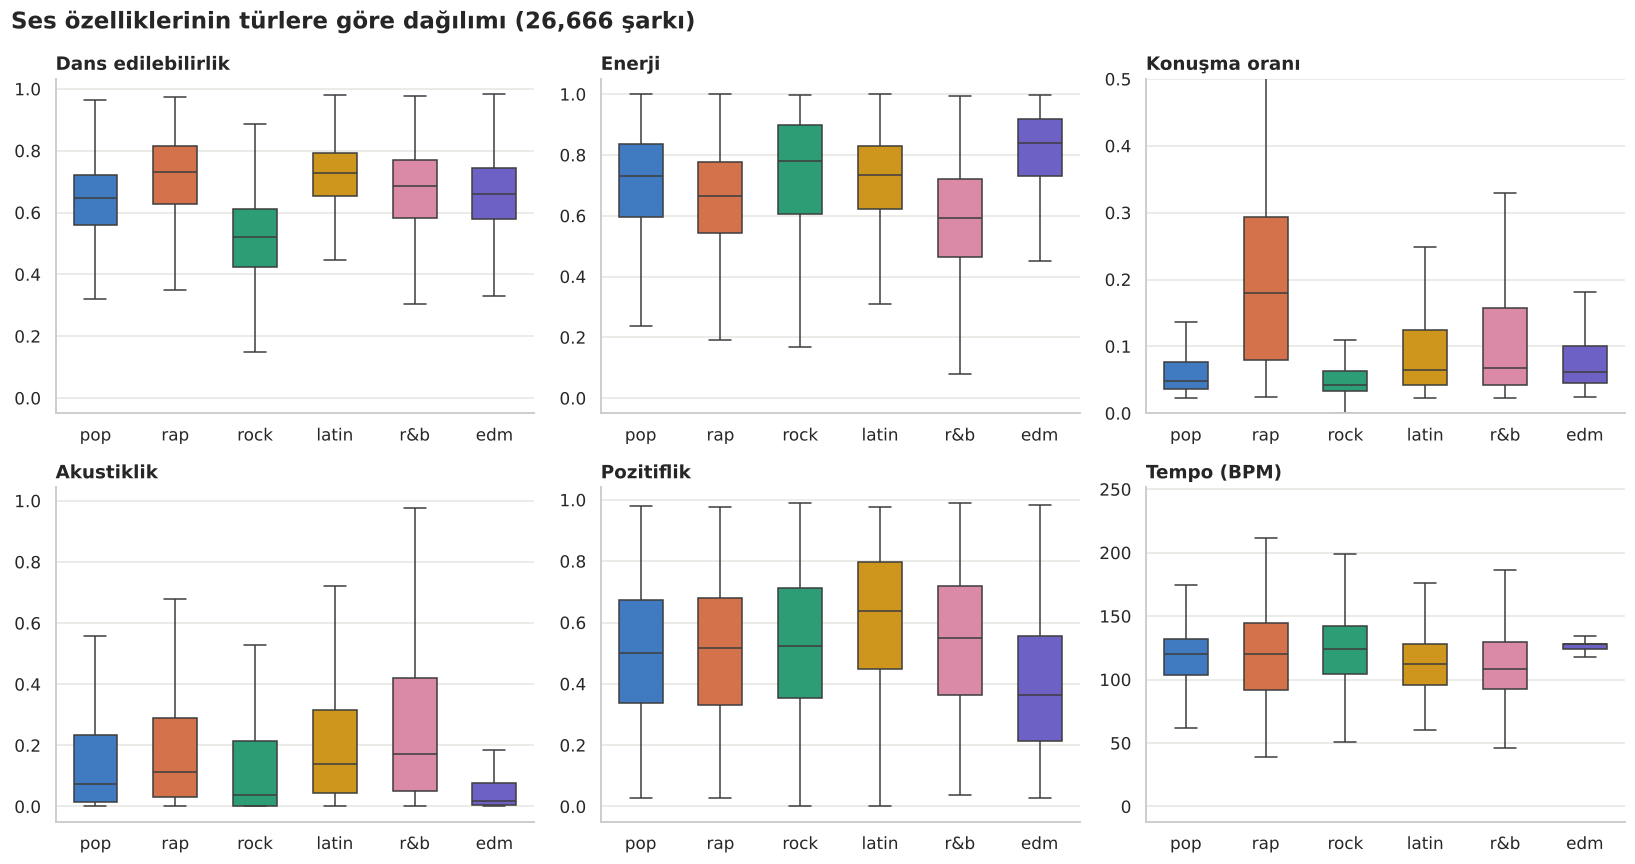

In [3]:
gosterilen = ["danceability", "energy", "speechiness", "acousticness", "valence", "tempo"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, oz in zip(axes.flat, gosterilen):
    sns.boxplot(data=tekil, x="playlist_genre", y=oz, order=TURLER, hue="playlist_genre",
                palette=RENK, ax=ax, width=0.55, fliersize=0, linewidth=1, legend=False)
    ax.set_title(TR[oz]); ax.set_xlabel(""); ax.set_ylabel("")
    if oz == "speechiness": ax.set_ylim(0, 0.5)
fig.suptitle(f"Ses özelliklerinin türlere göre dağılımı ({len(tekil):,} şarkı)", x=0.01, ha="left",
             fontweight="bold", fontsize=15)
plt.tight_layout()
plt.show()

### Radar grafiği: her türün parmak izi
Altı türü üst üste koymak okunmaz olacağı için her türü ayrı panelde, **tüm şarkıların ortalaması** (gri kesikli) referansıyla gösteriyoruz.

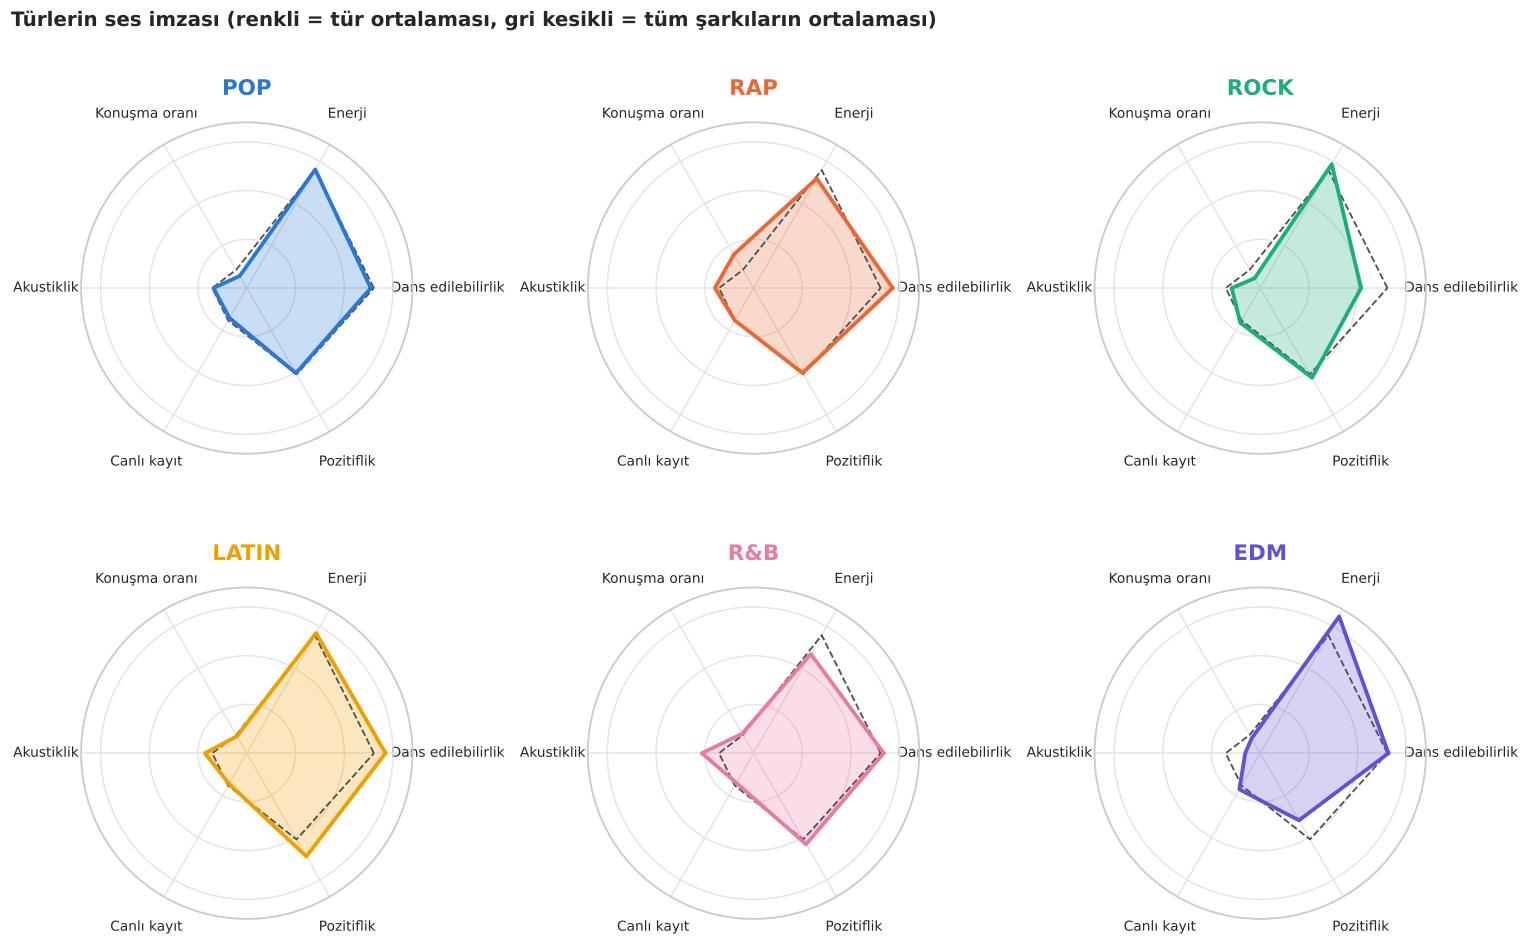

In [4]:
radar = ["danceability", "energy", "speechiness", "acousticness", "liveness", "valence"]
ort = tekil.groupby("playlist_genre")[radar].mean().reindex(TURLER)
genel = tekil[radar].mean()
acilar = np.linspace(0, 2 * np.pi, len(radar), endpoint=False).tolist()
kapat = lambda v: list(v) + [v[0]]

fig, axes = plt.subplots(2, 3, figsize=(14, 9), subplot_kw=dict(polar=True))
for ax, tur in zip(axes.flat, TURLER):
    ax.plot(kapat(acilar), kapat(genel.values), color=GRI, lw=1.2, ls="--")
    ax.plot(kapat(acilar), kapat(ort.loc[tur].values), color=RENK[tur], lw=2.5)
    ax.fill(kapat(acilar), kapat(ort.loc[tur].values), color=RENK[tur], alpha=0.25)
    ax.set_xticks(acilar); ax.set_xticklabels([TR[r] for r in radar], fontsize=9)
    ax.tick_params(axis="x", pad=10)
    ax.set_ylim(0, 0.85); ax.set_yticks([0.25, 0.5, 0.75]); ax.set_yticklabels([])
    ax.set_title(tur.upper(), color=RENK[tur], fontsize=14, pad=18, loc="center")
fig.suptitle("Türlerin ses imzası (renkli = tür ortalaması, gri kesikli = tüm şarkıların ortalaması)",
             x=0.01, ha="left", fontweight="bold", fontsize=13)
plt.tight_layout()
plt.show()

## 4. İstatistiksel testler: türler gerçekten farklı mı?

Grafiklerde görülen farklar tesadüf olabilir mi? Dağılımlar normal olmadığı için parametrik olmayan **Kruskal–Wallis** testini kullanıyoruz. Ancak 26 bin şarkıda neredeyse her fark "anlamlı" çıkar; asıl önemli olan **farkın büyüklüğü**. Bunun için etki büyüklüğü **ε²** (epsilon-kare) hesaplıyoruz:

| ε² | Yorum |
|---|---|
| < 0,01 | önemsiz |
| 0,01 – 0,08 | küçük |
| 0,08 – 0,26 | orta |
| > 0,26 | büyük |

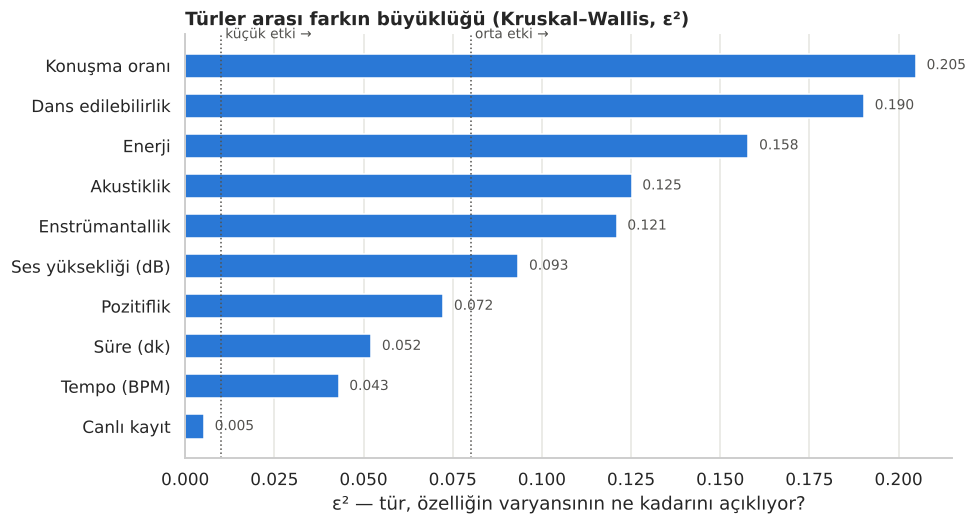

Tüm testlerde p < 1e-29. En ayırt edici: Konuşma oranı (ε² = 0.20); en az: Canlı kayıt (ε² = 0.005)


In [5]:
n, k = len(tekil), len(TURLER)
testler = []
for oz in OZELLIKLER:
    H, p = kruskal(*[tekil.loc[tekil.playlist_genre == t, oz] for t in TURLER])
    testler.append({"özellik": TR[oz], "H": H, "p": p, "ε²": (H - k + 1) / (n - k)})
testler = pd.DataFrame(testler).sort_values("ε²")

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(testler["özellik"], testler["ε²"], color=RENK["pop"], height=0.6)
for esik, ad in [(0.01, "küçük"), (0.08, "orta")]:
    ax.axvline(esik, color=GRI, ls=":", lw=1)
    ax.text(esik, len(testler) - 0.4, f" {ad} etki →", fontsize=9, color=GRI, va="bottom")
for i, v in enumerate(testler["ε²"]):
    ax.text(v + 0.003, i, f"{v:.3f}", va="center", fontsize=9, color=GRI)
ax.set_title("Türler arası farkın büyüklüğü (Kruskal–Wallis, ε²)")
ax.set_xlabel("ε² — tür, özelliğin varyansının ne kadarını açıklıyor?")
ax.grid(axis="y", visible=False)
plt.show()

print(f"Tüm testlerde p < {testler.p.max():.0e}. En ayırt edici: {testler['özellik'].iloc[-1]} "
      f"(ε² = {testler['ε²'].iloc[-1]:.2f}); en az: {testler['özellik'].iloc[0]} (ε² = {testler['ε²'].iloc[0]:.3f})")

> 💡 Konuşma oranı ve dans edilebilirlik türleri en iyi ayıran özellikler; *canlı kayıt* neredeyse hiç fark yaratmıyor. Bu, modelin hangi özelliklere yaslanacağına dair ilk ipucu.

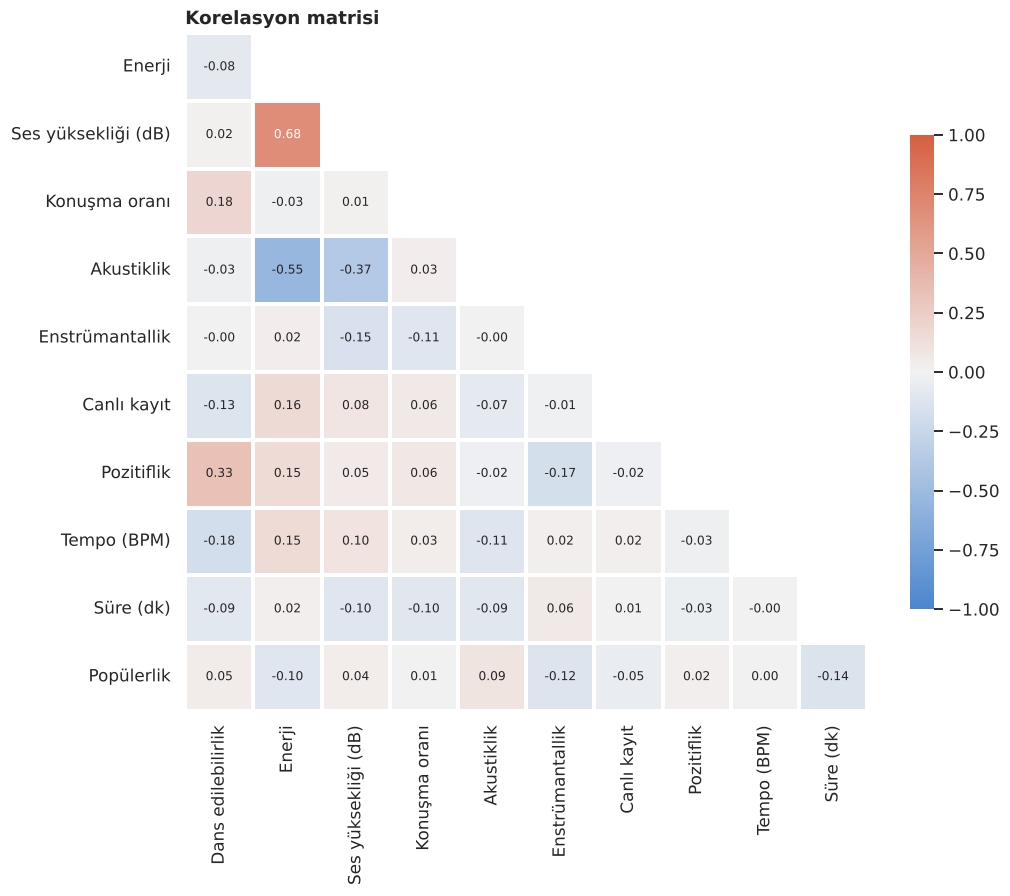

In [6]:
kor = sarkilar[OZELLIKLER + ["track_popularity"]].corr()
kor.index = kor.columns = [TR.get(c, "Popülerlik") for c in kor.columns]
kor = kor.iloc[1:, :-1]
maske = np.triu(np.ones_like(kor, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(kor, mask=maske, cmap=sns.diverging_palette(250, 20, s=75, l=55, as_cmap=True),
            center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 8},
            linewidths=1.5, linecolor="white", cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Korelasyon matrisi"); ax.grid(False)
plt.show()

## 5. Duygu haritası

Müzik psikolojisinde sık kullanılan **Russell'ın duygu modeli**, duyguları iki eksende konumlandırır: *pozitiflik* (olumlu ↔ olumsuz) ve *uyarılma* (enerjik ↔ sakin). Spotify'ın `valence` ve `energy` değerleri bu iki eksene denk geliyor. Her şarkıyı dört bölgeden birine yerleştiriyoruz:

| | düşük pozitiflik | yüksek pozitiflik |
|---|---|---|
| **yüksek enerji** | 😠 Gergin / öfkeli | 😄 Mutlu / coşkulu |
| **düşük enerji** | 😢 Hüzünlü | 😌 Sakin / huzurlu |

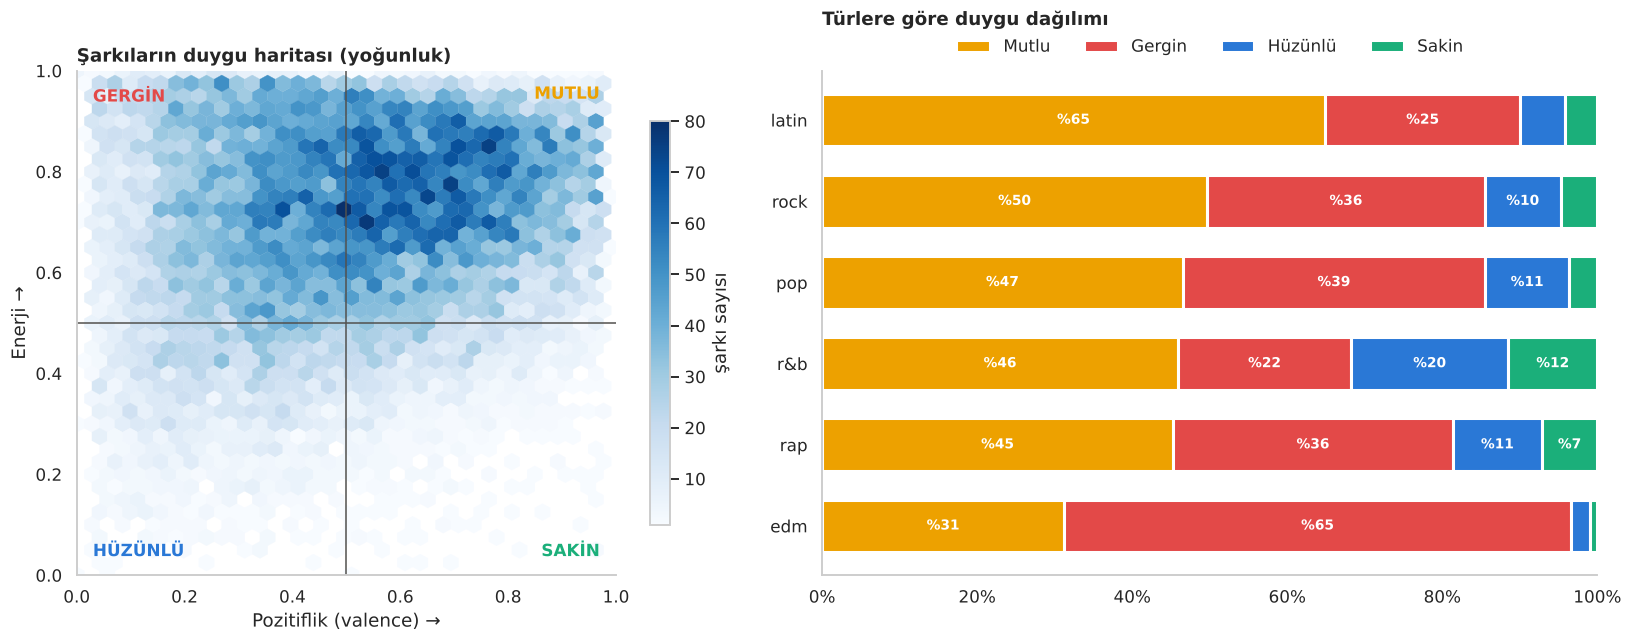

In [7]:
DUYGULAR = ["Mutlu", "Gergin", "Hüzünlü", "Sakin"]
DUYGU_RENK = {"Mutlu": "#eda100", "Gergin": "#e34948", "Hüzünlü": "#2a78d6", "Sakin": "#1baf7a"}

def duygu(v, e):
    return np.select([(v >= 0.5) & (e >= 0.5), (v < 0.5) & (e >= 0.5), (v < 0.5) & (e < 0.5)],
                     ["Mutlu", "Gergin", "Hüzünlü"], "Sakin")

sarkilar["duygu"] = duygu(sarkilar.valence, sarkilar.energy)
tekil["duygu"] = duygu(tekil.valence, tekil.energy)

fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1, 1.15]})
ax = axes[0]
hb = ax.hexbin(sarkilar.valence, sarkilar.energy, gridsize=35, cmap="Blues", mincnt=1, linewidths=0.2)
ax.axhline(0.5, color=GRI, lw=1); ax.axvline(0.5, color=GRI, lw=1)
for x, y, d in [(0.97, 0.97, "Mutlu"), (0.03, 0.97, "Gergin"), (0.03, 0.03, "Hüzünlü"), (0.97, 0.03, "Sakin")]:
    ax.text(x, y, d.upper().replace("I", "İ") if d != "Hüzünlü" else "HÜZÜNLÜ", transform=ax.transAxes,
            ha="right" if x > 0.5 else "left", va="top" if y > 0.5 else "bottom",
            fontweight="bold", color=DUYGU_RENK[d], fontsize=11)
ax.set_xlabel("Pozitiflik (valence) →"); ax.set_ylabel("Enerji →")
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.grid(False)
ax.set_title("Şarkıların duygu haritası (yoğunluk)")
fig.colorbar(hb, ax=ax, shrink=0.8, label="şarkı sayısı")

ax = axes[1]
pay = pd.crosstab(tekil.playlist_genre, tekil.duygu, normalize="index").reindex(TURLER)[DUYGULAR] * 100
pay = pay.sort_values("Mutlu")
sol = np.zeros(len(pay))
for d in DUYGULAR:
    ax.barh(pay.index, pay[d], left=sol, color=DUYGU_RENK[d], label=d, height=0.65, edgecolor="white", linewidth=2)
    for i, (v, l) in enumerate(zip(pay[d], sol)):
        if v >= 7:
            ax.text(l + v / 2, i, f"%{v:.0f}", ha="center", va="center", fontsize=9, color="white", fontweight="bold")
    sol += pay[d].values
ax.set_xlim(0, 100); ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.legend(ncol=4, loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False)
ax.set_title("Türlere göre duygu dağılımı", pad=30); ax.grid(False)
plt.tight_layout()
plt.show()

> 💡 **Latin** müziğin üçte ikisi "mutlu" bölgede; **EDM** ise yüksek enerjisine rağmen ağırlıklı olarak "gergin" — enerjik ama karanlık. Hüzünlü şarkıların en yüksek payı **r&b**'de.

## 6. Zaman içinde müzik

Albüm çıkış yılına göre dört özelliğin medyanını izliyoruz. Eğilimlerin istatistiksel olarak anlamlı olup olmadığını **Spearman sıra korelasyonu** ile test ediyoruz.

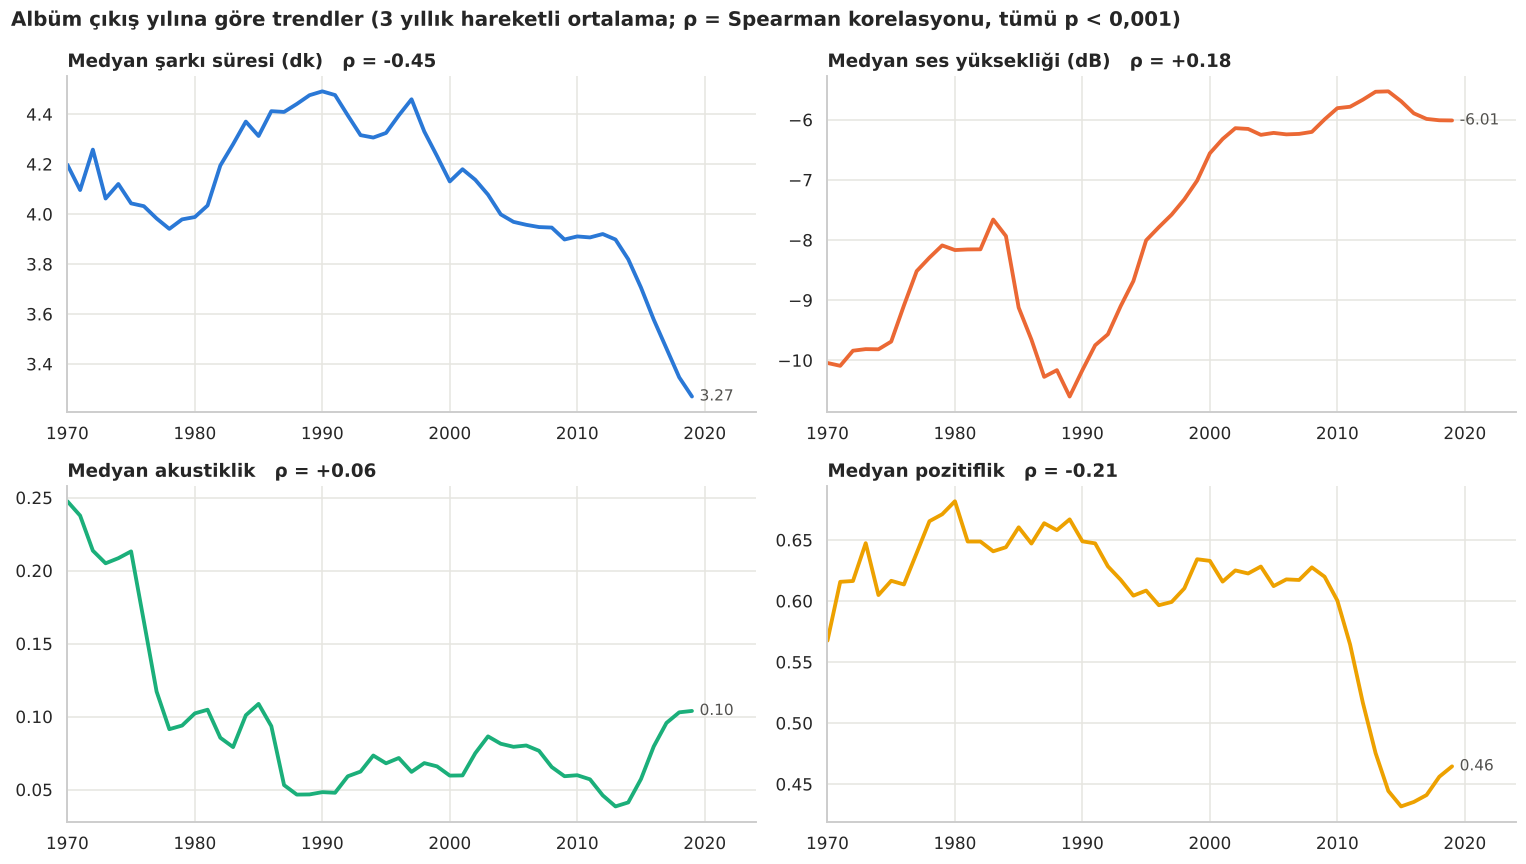

,Şarkı sayısı,Süre (dk),Ses (dB),Pozitiflik,Hüzünlü+gergin payı (%)
onyil,,,,,
1970,783,4.04,-9.34,0.63,31.55
1980,1090,4.32,-9.25,0.65,27.52
1990,2081,4.36,-8.21,0.62,30.32
2000,3807,3.99,-6.24,0.62,31.57
2010,19830,3.46,-5.88,0.47,54.75


In [8]:
z = sarkilar[sarkilar.yil.between(1970, 2019)]
izlenen = {"duration_min": ("Medyan şarkı süresi (dk)", RENK["pop"]),
           "loudness": ("Medyan ses yüksekliği (dB)", RENK["rap"]),
           "acousticness": ("Medyan akustiklik", RENK["rock"]),
           "valence": ("Medyan pozitiflik", RENK["latin"])}
yillik = z.groupby("yil").agg(**{k: (k, "median") for k in izlenen}, n=("track_id", "size"))
yillik = yillik[yillik.n >= 30].rolling(3, center=True, min_periods=1).mean()

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, (kol, (baslik, renk)) in zip(axes.flat, izlenen.items()):
    ax.plot(yillik.index, yillik[kol], color=renk, lw=2.5)
    son = yillik[kol].iloc[-1]
    ax.annotate(f"{son:.2f}", (yillik.index[-1], son), xytext=(5, 0), textcoords="offset points",
                va="center", fontsize=10, color=GRI)
    rho, p = spearmanr(z.yil, z[kol])
    ax.set_title(f"{baslik}   ρ = {rho:+.2f}", fontsize=12)
    ax.set_xlim(yillik.index.min(), yillik.index.max() + 5)
fig.suptitle("Albüm çıkış yılına göre trendler (3 yıllık hareketli ortalama; ρ = Spearman korelasyonu, tümü p < 0,001)",
             x=0.01, ha="left", fontweight="bold", fontsize=13)
plt.tight_layout()
plt.show()

onyil = z.assign(onyil=(z.yil // 10 * 10).astype(int)).groupby("onyil")
tablo = pd.DataFrame({"Şarkı sayısı": onyil.size(), "Süre (dk)": onyil.duration_min.median(),
                      "Ses (dB)": onyil.loudness.median(), "Pozitiflik": onyil.valence.median(),
                      "Hüzünlü+gergin payı (%)": onyil.duygu.apply(lambda s: s.isin(["Hüzünlü", "Gergin"]).mean() * 100)})
tablo.round(2)

> 💡 Üç güçlü hikâye: şarkılar **kısalıyor** (yayın platformlarında dinlenme başına ödeme modeli), **yükseliyor** (*loudness war*) ve 2010'larda belirgin şekilde **hüzünleniyor** — pozitiflik medyanı on yıl içinde ~0,62'den ~0,47'ye düşüyor.

## 7. t-SNE ile şarkı haritası

10 boyutlu ses özelliği uzayını **t-SNE** ile 2 boyuta indiriyoruz. Benzer şarkılar haritada yan yana düşer. Model türleri ayırt edebilecek mi sorusuna görsel bir ön cevap: türler ada mı oluşturuyor, yoksa iç içe mi?

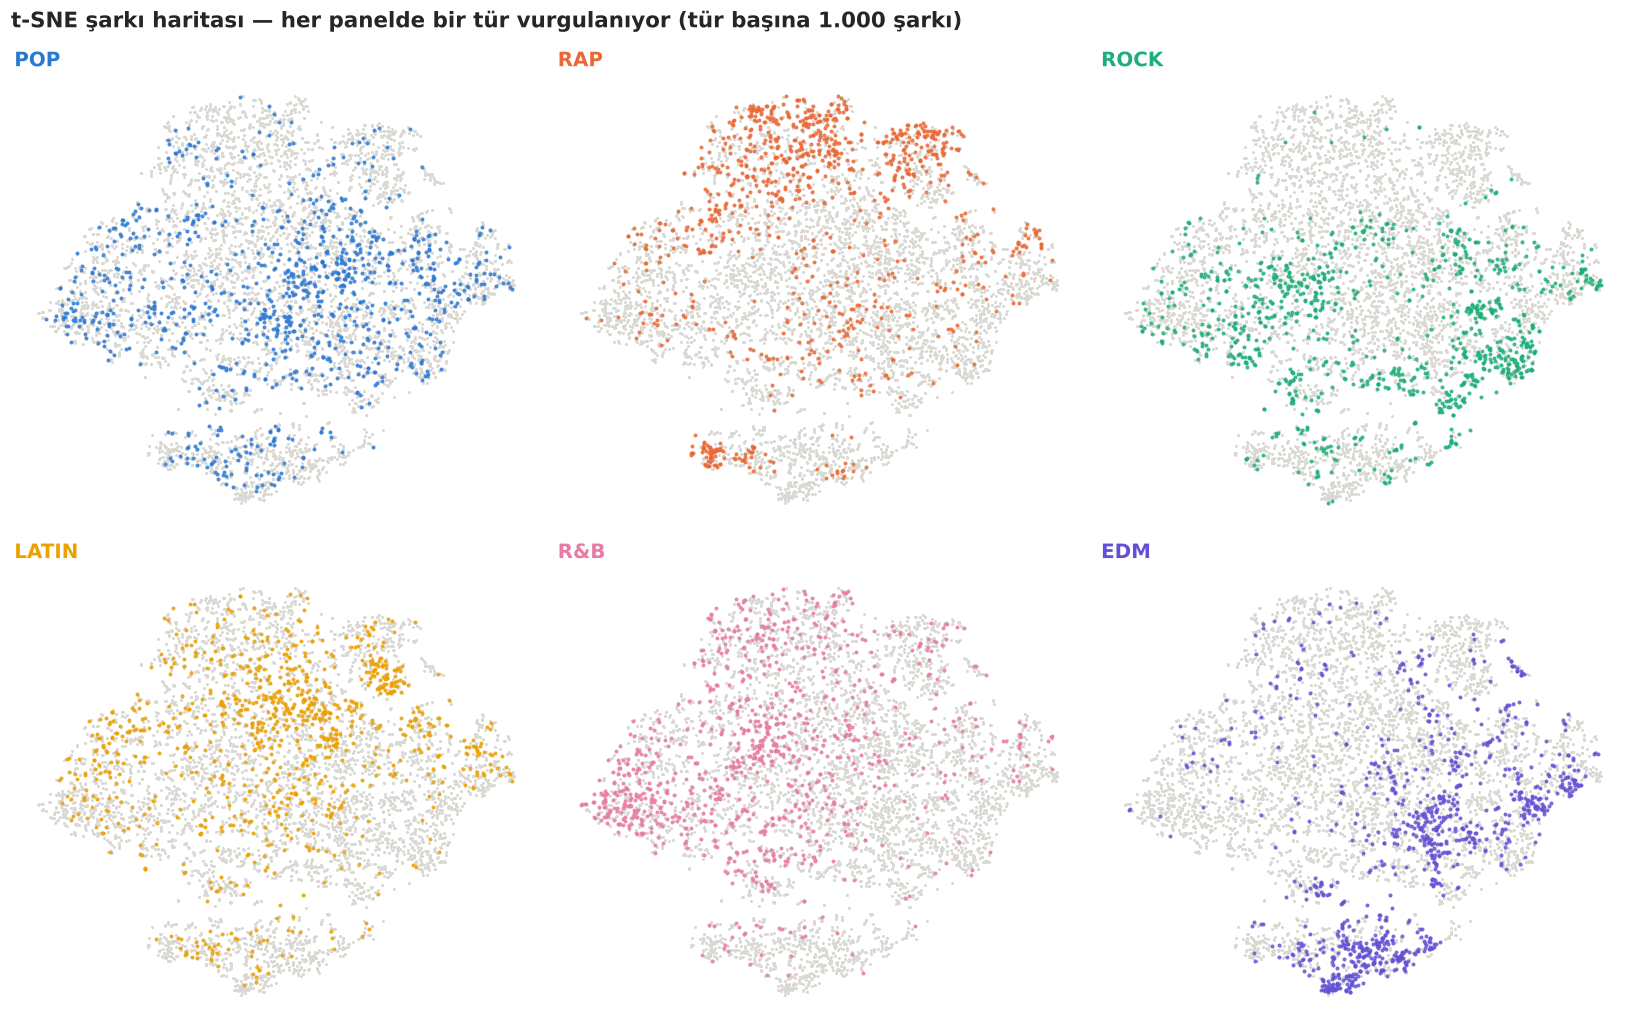

In [9]:
orneklem = tekil.groupby("playlist_genre").sample(1000, random_state=SEED)
gomme = TSNE(n_components=2, perplexity=40, init="pca", learning_rate="auto", random_state=SEED) \
    .fit_transform(StandardScaler().fit_transform(orneklem[OZELLIKLER]))
orneklem[["x", "y"]] = gomme

fig, axes = plt.subplots(2, 3, figsize=(15, 9.5), sharex=True, sharey=True)
for ax, tur in zip(axes.flat, TURLER):
    ax.scatter(orneklem.x, orneklem.y, s=4, color="#d9d8d3", linewidths=0)
    g = orneklem[orneklem.playlist_genre == tur]
    ax.scatter(g.x, g.y, s=7, color=RENK[tur], alpha=0.8, linewidths=0)
    ax.set_title(tur.upper(), color=RENK[tur], fontsize=13)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for s in ax.spines.values(): s.set_visible(False)
fig.suptitle("t-SNE şarkı haritası — her panelde bir tür vurgulanıyor (tür başına 1.000 şarkı)",
             x=0.01, ha="left", fontweight="bold", fontsize=14)
plt.tight_layout()
plt.show()

> 💡 **Rap** haritanın üst kısmında, **EDM** ise alttaki ayrı bir adada toplanıyor; **rock** orta bantta yoğunlaşıyor. **Pop** ve **r&b** ise neredeyse her yere dağılmış durumda. Bu, aşağıda modelin pop'u tanımakta neden zorlanacağını önceden haber veriyor.

## 8. Popülerlik: ses mi, sanatçı mı?

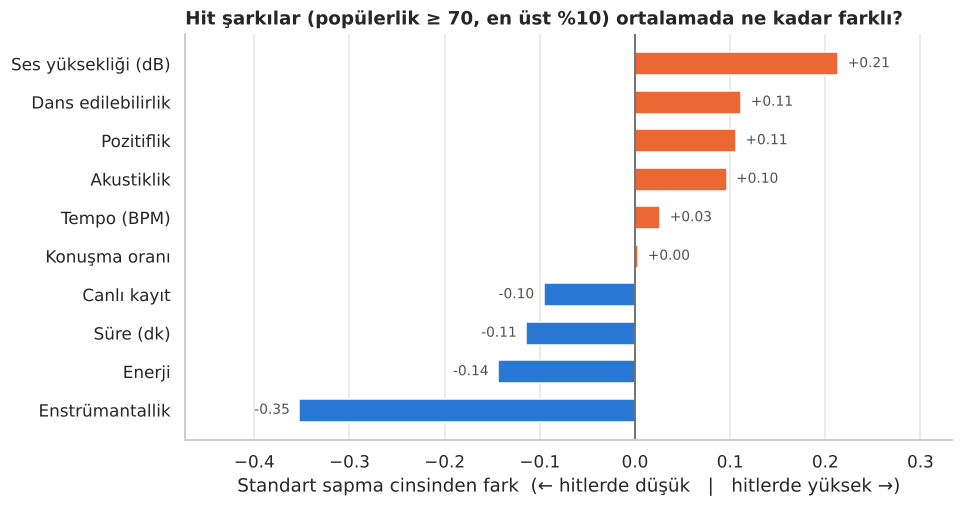

In [10]:
p = sarkilar[sarkilar.track_popularity > 0].copy()     # 0 puanlılar çoğunlukla kaldırılmış/eksik kayıtlar
esik = p.track_popularity.quantile(0.9)
hit, diger = p[p.track_popularity >= esik], p[p.track_popularity < esik]
fark = ((hit[OZELLIKLER].mean() - diger[OZELLIKLER].mean()) / p[OZELLIKLER].std()).sort_values()

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.barh([TR[i] for i in fark.index], fark.values, color=[RENK["rap"] if v > 0 else RENK["pop"] for v in fark], height=0.6)
ax.axvline(0, color=GRI, lw=1)
for i, v in enumerate(fark.values):
    ax.text(v + (0.01 if v >= 0 else -0.01), i, f"{v:+.2f}", va="center", ha="left" if v >= 0 else "right",
            fontsize=9, color=GRI)
ax.set_xlim(fark.min() - 0.12, fark.max() + 0.12)
ax.set_title(f"Hit şarkılar (popülerlik ≥ {esik:.0f}, en üst %10) ortalamada ne kadar farklı?")
ax.set_xlabel("Standart sapma cinsinden fark  (← hitlerde düşük   |   hitlerde yüksek →)")
ax.grid(axis="y", visible=False)
plt.show()

### Popülerliği tahmin edebilir miyiz?

Üç adımlı bir deney kuruyoruz ve her adımda modele yeni bilgi ekliyoruz:
1. Yalnızca **ses özellikleri**
2. \+ **çıkış yılı ve tür**
3. \+ **sanatçı bilgisi**: sanatçının diğer şarkılarının ortalama popülerliği ve şarkı sayısı

⚠️ Sanatçı ortalamasını doğrudan hesaplamak **veri sızıntısı** yaratır: tahmin edilen şarkının kendi puanı ortalamaya karışır. Bunu önlemek için **katlama dışı (out-of-fold) hedef kodlama** kullanıyoruz: her şarkının sanatçı ortalaması, o şarkının bulunmadığı katlardan hesaplanıyor.

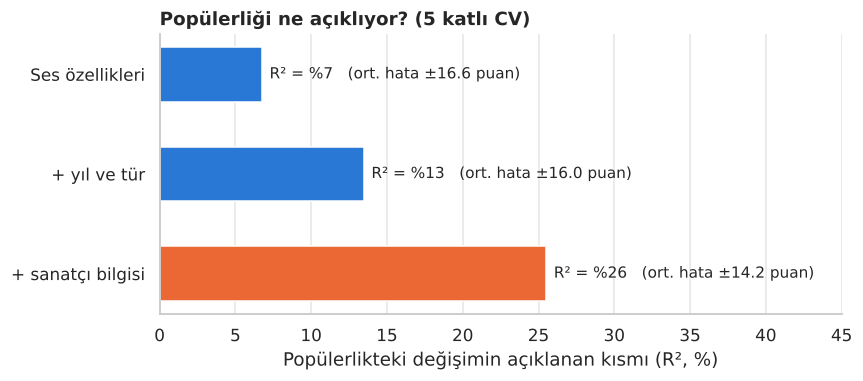

In [11]:
p["yil"] = p.yil.fillna(p.yil.median())
kf = KFold(5, shuffle=True, random_state=SEED)
genel_ort = p.track_popularity.mean()
p["sanatci_pop"], p["sanatci_n"] = np.nan, 0.0
for tr, va in kf.split(p):
    a = p.iloc[tr].groupby("track_artist").track_popularity.agg(["mean", "count"])
    yumusak = (a["mean"] * a["count"] + genel_ort * 10) / (a["count"] + 10)   # az şarkılı sanatçıları ortalamaya çek
    p.iloc[va, p.columns.get_loc("sanatci_pop")] = p.iloc[va].track_artist.map(yumusak).fillna(genel_ort).values
    p.iloc[va, p.columns.get_loc("sanatci_n")] = p.iloc[va].track_artist.map(a["count"]).fillna(0).values

tur_dummy = pd.get_dummies(p.playlist_genre, prefix="tur")
deneyler = {"Ses özellikleri": p[OZELLIKLER],
            "+ yıl ve tür": pd.concat([p[OZELLIKLER + ["yil"]], tur_dummy], axis=1),
            "+ sanatçı bilgisi": pd.concat([p[OZELLIKLER + ["yil", "sanatci_pop", "sanatci_n"]], tur_dummy], axis=1)}
pop_sonuc = {}
for ad, Xp in deneyler.items():
    tahmin = cross_val_predict(HistGradientBoostingRegressor(max_iter=300, random_state=SEED), Xp, p.track_popularity,
                               cv=kf, n_jobs=-1)
    pop_sonuc[ad] = {"R²": r2_score(p.track_popularity, tahmin), "MAE": mean_absolute_error(p.track_popularity, tahmin)}
pop_sonuc = pd.DataFrame(pop_sonuc).T

fig, ax = plt.subplots(figsize=(8, 3.3))
ax.barh(pop_sonuc.index[::-1], pop_sonuc["R²"][::-1] * 100, color=[RENK["pop"], RENK["pop"], RENK["rap"]][::-1], height=0.55)
for i, (r2, mae) in enumerate(zip(pop_sonuc["R²"][::-1], pop_sonuc["MAE"][::-1])):
    ax.text(r2 * 100 + 0.5, i, f"R² = %{r2*100:.0f}   (ort. hata ±{mae:.1f} puan)", va="center", fontsize=10)
ax.set_xlim(0, 45); ax.set_xlabel("Popülerlikteki değişimin açıklanan kısmı (R², %)")
ax.set_title("Popülerliği ne açıklıyor? (5 katlı CV)"); ax.grid(axis="y", visible=False)
plt.show()

> 💡 Ses özellikleri popülerliğin yalnızca küçük bir kısmını açıklıyor. Sanatçı bilgisi eklenince açıklama gücü yaklaşık **3–4 katına** çıkıyor: bir şarkının nasıl *duyulduğundan* çok, *kimin* söylediği önemli. Yine de R²'nin düşük kalması, popülerliğin büyük ölçüde verideki hiçbir değişkenle yakalanamayan faktörlere (pazarlama, viral anlar, zamanlama) bağlı olduğunu gösteriyor.

## 9. 🤖 Tür tahmini

Amaç: bir şarkının 6 türden hangisine ait olduğunu tahmin etmek (rastgele tahmin: %16,7). Modele adım adım daha fazla bilgi vererek her bilgi türünün katkısını ölçeceğiz:

| Bilgi grubu | İçerik |
|---|---|
| 🎚️ **Ses** | 10 ses özelliği + ton, majör/minör, çıkış yılı |
| 🏷️ **Şarkı adı ipuçları** | adında *remix*, *feat.*, *remaster* geçiyor mu, İspanyolca mı, ne kadar uzun |
| 🔤 **Şarkı adı metin modeli** | adın harf dizilerinden (TF-IDF) türü tahmin eden ayrı bir model — çıktısı ana modele girdi olur (*stacking*) |
| 🎤 **Sanatçı** *(ayrı senaryo)* | sanatçının diğer şarkılarının tür dağılımı |

Veriyi en başta **%80 eğitim / %20 test** olarak ayırıyoruz. Tüm model seçimi ve ayarlama eğitim verisinde yapılıyor; test verisine yalnızca değerlendirme için bakılıyor.

⚠️ Metin modeli ve sanatçı özellikleri **hedef değişkenden** türetildiği için eğitim verisinde **katlama dışı (out-of-fold)** hesaplanıyor: her şarkının değeri, o şarkıyı görmemiş bir modelden geliyor. Aksi halde model kendi cevabını girdi olarak görür ve sonuçlar sahte biçimde şişer.

In [12]:
import lightgbm as lgb
import optuna
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import GroupKFold

tekil["yil"] = tekil.yil.fillna(tekil.yil.median())
isim = tekil.track_name.str.lower()
tekil["remix"] = isim.str.contains(r"remix|\bmix\b|\bedit\b").astype(int)
tekil["feat"] = isim.str.contains(r"feat\.|ft\.|\bwith\b").astype(int)
tekil["remaster"] = isim.str.contains("remaster").astype(int)
tekil["ispanyolca"] = isim.str.contains(r"[ñáéíóú¿¡]|\b(?:el|la|que|mi|tu|amor|te|de)\b").astype(int)
tekil["isim_uzunluk"] = isim.str.len()

SES = OZELLIKLER + ["key", "mode", "yil"]
ISIM = ["remix", "feat", "remaster", "ispanyolca", "isim_uzunluk"]
SINIFLAR = sorted(TURLER)
METIN = [f"metin_{t}" for t in SINIFLAR]
SANATCI = [f"sanatci_{t}" for t in SINIFLAR]
TR.update({"remix": "Adında remix/mix", "feat": "Adında feat./with", "remaster": "Adında remaster",
           "ispanyolca": "Adı İspanyolca", "isim_uzunluk": "Ad uzunluğu",
           **{f"metin_{t}": f"Ad metni → {t}" for t in SINIFLAR},
           **{f"sanatci_{t}": f"Sanatçı → {t}" for t in SINIFLAR}})

egitim_idx, test_idx = train_test_split(tekil.index, test_size=0.2, stratify=tekil.playlist_genre, random_state=SEED)
egitim, test = tekil.loc[egitim_idx].copy(), tekil.loc[test_idx].copy()
y_egitim, y_test = egitim.playlist_genre, test.playlist_genre
cv5 = StratifiedKFold(5, shuffle=True, random_state=SEED)

print(f"Eğitim: {len(egitim):,}  |  Test: {len(test):,}")
print("Şarkı adı ipuçlarının türlere göre görülme oranı (%):")
(egitim.groupby("playlist_genre")[["remix", "feat", "remaster", "ispanyolca"]].mean().reindex(TURLER) * 100).round(1)

Eğitim: 21,332  |  Test: 5,334
Şarkı adı ipuçlarının türlere göre görülme oranı (%):


,remix,feat,remaster,ispanyolca
playlist_genre,,,,
pop,9.1,9.1,0.9,2.6
rap,3.2,10.3,0.6,4.1
rock,1.9,2.1,13.2,1.5
latin,9.4,8.8,0.4,25.6
r&b,4.2,10.2,1.0,2.0
edm,33.2,10.6,0.0,1.4


### 9.1 Şarkı adından tür tahmini (metin modeli)
Şarkı adlarını 2–4 harflik parçalara bölüp (*TF-IDF karakter n-gramları*) lojistik regresyonla türü tahmin ediyoruz. Bu model tek başına zayıf olabilir ama ses özelliklerinin göremediği bir bilgiyi (dil, yazım alışkanlıkları) yakalıyor.

In [13]:
metin_modeli = make_pipeline(
    TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), min_df=3, sublinear_tf=True),
    LogisticRegression(max_iter=2000, C=2))
egitim_ad, test_ad = egitim.track_name.str.lower(), test.track_name.str.lower()

egitim[METIN] = cross_val_predict(metin_modeli, egitim_ad, y_egitim, cv=cv5, method="predict_proba")  # katlama dışı
metin_modeli.fit(egitim_ad, y_egitim)
test[METIN] = metin_modeli.predict_proba(test_ad)
print(f"Yalnızca şarkı adıyla doğruluk (katlama dışı): %{accuracy_score(y_egitim, np.array(SINIFLAR)[egitim[METIN].values.argmax(1)])*100:.1f}")

# Her tür için en belirleyici harf dizileri
kelimeler = metin_modeli[0].get_feature_names_out()
katsayi = metin_modeli[1].coef_
pd.DataFrame({t: [repr(kelimeler[j]) for j in np.argsort(katsayi[i])[::-1][:8]]
              for i, t in enumerate(SINIFLAR)})[TURLER]

Yalnızca şarkı adıyla doğruluk (katlama dışı): %40.4


,pop,rap,rock,latin,r&b,edm
0,'4e',' lil','rema','a ','ス ','mix'
1,' r ','lil ','2011','o ','sing',' rav'
2,' la ','tha ','011 ','os ',' u ','ix'
3,' ep ','lil','cars','ré','d)','mix '
4,'driv','а ','emas',' te ','d) ','ix '
5,'y. ','sent','mast','as ','j.',' ao'
6,"' ""'",'dite','9 ',' el ','j. ','emix'
7,'c ','cz',' 201',' es','iti','is '


> 💡 Model kendi kendine anlamlı ipuçları buluyor: **latin** için İspanyolca kalıplar (*' el '*, *'os '*, *' te '*), **rock** için yeniden basım izleri (*'rema'*, *'2011'*, *'mast'*), **EDM** için *'mix'* / *'emix'*, **rap** için *'lil'* (Lil Wayne, Lil Baby...). Şarkı adı tek başına %40 doğruluk veriyor; rastgele tahminin 2,4 katı.

### 9.2 Sanatçı özellikleri (ayrı senaryo)
Her şarkı için sanatçının **diğer** şarkılarının tür dağılımını hesaplıyoruz. Test şarkılarında yalnızca eğitim verisindeki şarkılar kullanılıyor; sanatçı eğitimde hiç yoksa değer boş kalıyor (LightGBM boş değerleri kendisi işliyor).

In [14]:
def sanatci_dagilimi(kaynak, hedef):
    tablo = pd.crosstab(kaynak.track_artist, kaynak.playlist_genre).reindex(columns=SINIFLAR, fill_value=0)
    return (tablo.T / tablo.sum(1)).T.reindex(hedef.track_artist).values

kod = np.full((len(egitim), len(SINIFLAR)), np.nan)
for tr_i, va_i in cv5.split(egitim, y_egitim):                       # katlama dışı
    kod[va_i] = sanatci_dagilimi(egitim.iloc[tr_i], egitim.iloc[va_i])
egitim[SANATCI] = kod
test[SANATCI] = sanatci_dagilimi(egitim, test)
print(f"Test şarkılarının %{test[SANATCI[0]].notna().mean()*100:.0f}'inin sanatçısı eğitim verisinde de var.")

Test şarkılarının %72'inin sanatçısı eğitim verisinde de var.


### 9.3 Model karşılaştırması (yalnızca ses özellikleri)

In [15]:
modeller = {
    "Lojistik Regresyon": make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)),
    "Random Forest": RandomForestClassifier(n_estimators=400, min_samples_leaf=2, max_features=0.5, n_jobs=-1, random_state=SEED),
    "HistGradientBoosting": HistGradientBoostingClassifier(max_iter=300, learning_rate=0.06, random_state=SEED),
    "LightGBM": lgb.LGBMClassifier(n_estimators=500, learning_rate=0.03, num_leaves=48, subsample=0.8, subsample_freq=1,
                                   colsample_bytree=0.7, verbose=-1, random_state=SEED, n_jobs=-1),
}
for ad, m in modeller.items():
    skor = cross_val_score(m, egitim[SES], y_egitim, cv=cv5, n_jobs=1 if ad != "Lojistik Regresyon" else -1)
    print(f"{ad:22s} → %{skor.mean()*100:.1f} (± {skor.std()*100:.1f})")

Lojistik Regresyon     → %50.2 (± 0.9)


Random Forest          → %61.2 (± 0.9)


HistGradientBoosting   → %60.3 (± 0.6)


LightGBM               → %61.6 (± 0.5)


### 9.4 Hiperparametre optimizasyonu: Optuna

**Optuna**, rastgele arama yerine **Bayesçi optimizasyon** (TPE) kullanır: önceki denemelerin sonuçlarından öğrenip umut verici bölgelere odaklanır. Her denemede LightGBM'i eğitim verisinin %80'iyle eğitip kalan %20'de ölçüyoruz; **erken durdurma** ağaç sayısını otomatik belirliyor. Arama tüm bilgi gruplarıyla (ses + şarkı adı) yapılıyor; 30 deneme ~3 dakika sürüyor.

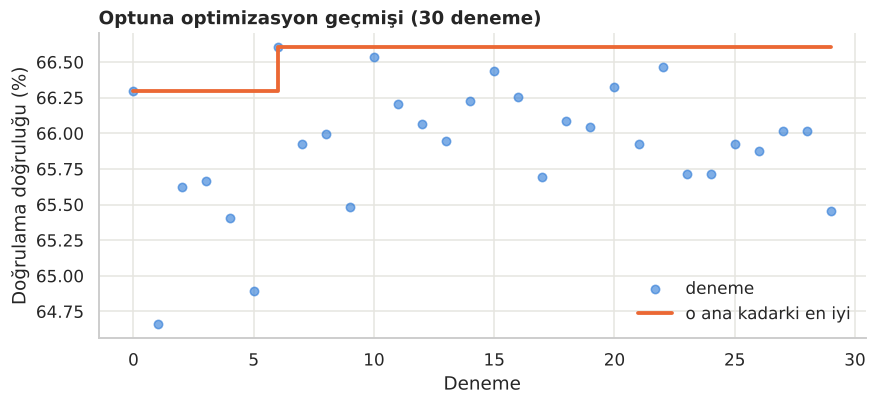

En iyi doğrulama doğruluğu: %66.6  |  ağaç sayısı: 237


,learning_rate,num_leaves,min_child_samples,subsample,colsample_bytree,reg_lambda,reg_alpha
en iyi değer,0.0317,106.0,17.0,0.865,0.587,0.1203,0.1538


In [16]:
TUM = SES + ISIM + METIN
X_a, X_d, y_a, y_d = train_test_split(egitim[TUM], y_egitim, test_size=0.2, stratify=y_egitim, random_state=SEED)

def amac(deneme):
    p = dict(learning_rate=deneme.suggest_float("learning_rate", 0.03, 0.15, log=True),
             num_leaves=deneme.suggest_int("num_leaves", 16, 128, log=True),
             min_child_samples=deneme.suggest_int("min_child_samples", 10, 100, log=True),
             subsample=deneme.suggest_float("subsample", 0.6, 1.0),
             colsample_bytree=deneme.suggest_float("colsample_bytree", 0.4, 1.0),
             reg_lambda=deneme.suggest_float("reg_lambda", 1e-3, 10, log=True),
             reg_alpha=deneme.suggest_float("reg_alpha", 1e-3, 10, log=True))
    m = lgb.LGBMClassifier(n_estimators=1500, subsample_freq=1, verbose=-1, random_state=SEED, n_jobs=-1, **p)
    m.fit(X_a, y_a, eval_set=[(X_d, y_d)], callbacks=[lgb.early_stopping(50, verbose=False)])
    deneme.set_user_attr("agac", m.best_iteration_)
    return accuracy_score(y_d, m.predict(X_d))

optuna.logging.set_verbosity(optuna.logging.WARNING)
calisma = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
calisma.optimize(amac, n_trials=30)
EN_IYI = dict(calisma.best_params, n_estimators=int(calisma.best_trial.user_attrs["agac"] * 1.1))

gecmis = calisma.trials_dataframe()
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.scatter(gecmis.number, gecmis.value * 100, color=RENK["pop"], s=30, alpha=0.6, label="deneme")
ax.plot(gecmis.number, gecmis.value.cummax() * 100, color=RENK["rap"], lw=2.5, drawstyle="steps-post", label="o ana kadarki en iyi")
ax.set_xlabel("Deneme"); ax.set_ylabel("Doğrulama doğruluğu (%)")
ax.set_title(f"Optuna optimizasyon geçmişi ({len(gecmis)} deneme)"); ax.legend(frameon=False, loc="lower right")
plt.show()
print(f"En iyi doğrulama doğruluğu: %{calisma.best_value*100:.1f}  |  ağaç sayısı: {EN_IYI['n_estimators']}")
pd.Series(calisma.best_params).round(4).to_frame("en iyi değer").T

### 9.5 Adım adım test sonuçları

Ayarlı LightGBM'i her adımda bir bilgi grubu ekleyerek eğitiyor ve **test verisinde** ölçüyoruz. Son ana modelde LightGBM'i Random Forest ile **yumuşak oylama** (olasılık ortalaması) ensemble'ında birleştiriyoruz.

**İlk 2 doğruluk**: doğru tür, modelin en olası iki tahmini arasında mı? Pop gibi bulanık türler için daha adil bir ölçüt.

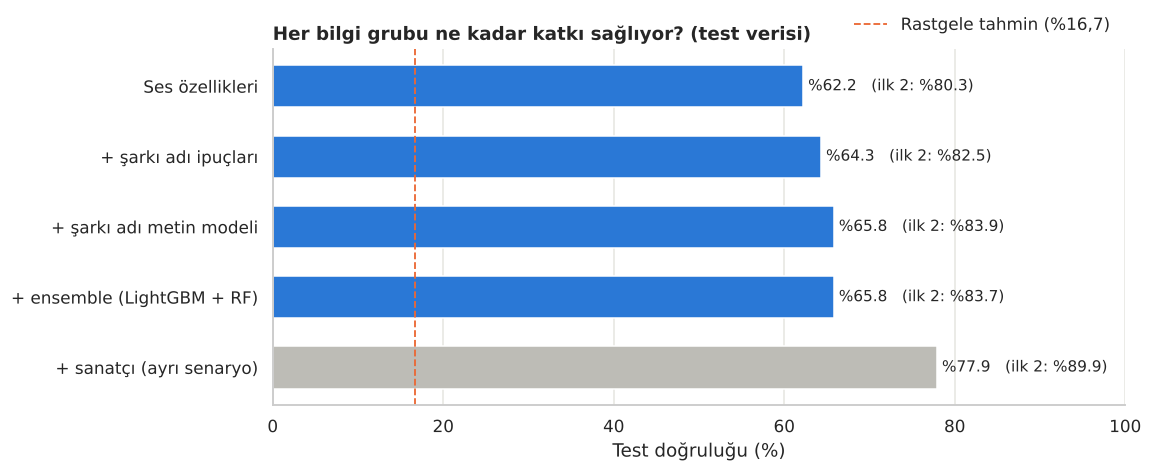

,Doğruluk,Macro F1,İlk 2 doğruluk
Ses özellikleri,0.622,0.613,0.803
+ şarkı adı ipuçları,0.643,0.635,0.825
+ şarkı adı metin modeli,0.658,0.653,0.839
+ ensemble (LightGBM + RF),0.658,0.653,0.837
+ sanatçı (ayrı senaryo),0.779,0.776,0.899


In [17]:
def lgbm():
    return lgb.LGBMClassifier(**EN_IYI, subsample_freq=1, verbose=-1, random_state=SEED, n_jobs=-1)

def degerlendir(m, kolonlar):
    m.fit(egitim[kolonlar], y_egitim)
    o = m.predict_proba(test[kolonlar])
    t_ = m.classes_[o.argmax(1)]
    return m, o, {"Doğruluk": accuracy_score(y_test, t_), "Macro F1": f1_score(y_test, t_, average="macro"),
                  "İlk 2 doğruluk": top_k_accuracy_score(y_test, o, k=2, labels=m.classes_)}

adimlar = {}
_, _, adimlar["Ses özellikleri"] = degerlendir(lgbm(), SES)
_, _, adimlar["+ şarkı adı ipuçları"] = degerlendir(lgbm(), SES + ISIM)
lgbm_son, _, adimlar["+ şarkı adı metin modeli"] = degerlendir(lgbm(), TUM)
rf_son = RandomForestClassifier(n_estimators=500, min_samples_leaf=2, max_features=0.4, n_jobs=-1, random_state=SEED)
model, olas, adimlar["+ ensemble (LightGBM + RF)"] = degerlendir(
    VotingClassifier([("lgbm", lgbm()), ("rf", rf_son)], voting="soft"), TUM)
_, _, adimlar["+ sanatçı (ayrı senaryo)"] = degerlendir(lgbm(), TUM + SANATCI)
adimlar = pd.DataFrame(adimlar).T
tahmin = model.classes_[olas.argmax(1)]

fig, ax = plt.subplots(figsize=(10, 4.2))
renkler = [RENK["pop"]] * 4 + ["#bdbcb6"]
ax.barh(adimlar.index[::-1], adimlar["Doğruluk"][::-1] * 100, color=renkler[::-1], height=0.6)
for i, (acc, top2) in enumerate(zip(adimlar["Doğruluk"][::-1], adimlar["İlk 2 doğruluk"][::-1])):
    ax.text(acc * 100 + 0.6, i, f"%{acc*100:.1f}   (ilk 2: %{top2*100:.1f})", va="center", fontsize=10)
ax.axvline(100 / 6, color=RENK["rap"], ls="--", lw=1.2, label="Rastgele tahmin (%16,7)")
ax.set_xlim(0, 100); ax.set_xlabel("Test doğruluğu (%)"); ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="lower right", bbox_to_anchor=(1.0, 1.0))
ax.set_title("Her bilgi grubu ne kadar katkı sağlıyor? (test verisi)")
plt.show()
adimlar.round(3)

> 💡 **Önemli ders:** Hiperparametre optimizasyonu tek başına sınırlı kazanç sağlıyor: ses özellikleriyle tavan **~%62**. Asıl artış modele **yeni bilgi** vermekten geliyor: şarkı adı ipuçları +2,1, metin modeli +1,5 puan. Ensemble bu sefer ek katkı sağlamadı, çünkü LightGBM metin bilgisini zaten iyi kullanıyor. Sanatçı bilgisi doğruluğu %78'e çıkarıyor ama bu farklı bir soru: "şarkının sesi neye benziyor" değil, "bu sanatçı genelde ne çalıyor". Bu yüzden ana model olarak **ses + şarkı adı** modelini kullanıyoruz.

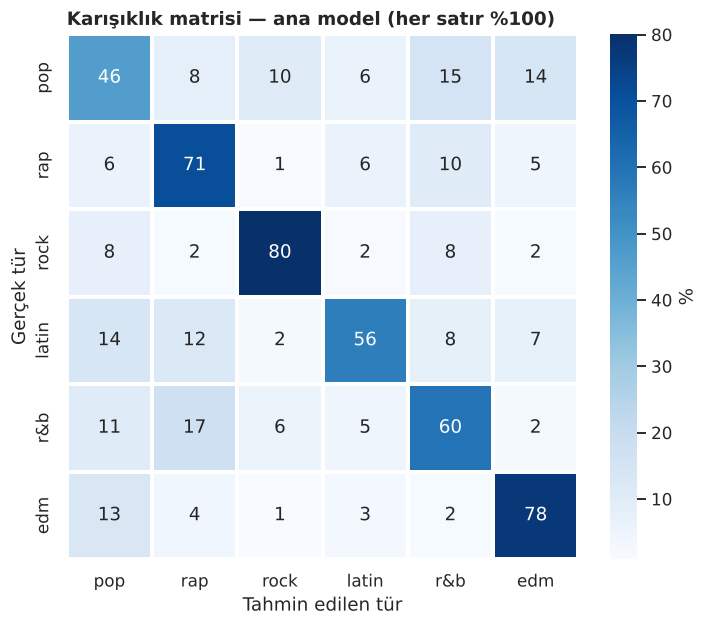

              precision    recall  f1-score   support

         pop      0.456     0.465     0.460       820
         rap      0.657     0.711     0.683       999
        rock      0.795     0.801     0.798       853
       latin      0.696     0.563     0.622       796
         r&b      0.589     0.596     0.592       890
         edm      0.746     0.776     0.760       976

    accuracy                          0.658      5334
   macro avg      0.656     0.652     0.653      5334
weighted avg      0.659     0.658     0.657      5334



In [18]:
cm = confusion_matrix(y_test, tahmin, labels=TURLER, normalize="true") * 100
fig, ax = plt.subplots(figsize=(7.5, 6.2))
sns.heatmap(cm, annot=True, fmt=".0f", cmap="Blues", xticklabels=TURLER, yticklabels=TURLER,
            linewidths=1.5, linecolor="white", cbar_kws={"label": "%"}, ax=ax)
ax.set_xlabel("Tahmin edilen tür"); ax.set_ylabel("Gerçek tür")
ax.set_title("Karışıklık matrisi — ana model (her satır %100)")
plt.show()
print(classification_report(y_test, tahmin, labels=TURLER, digits=3))

### 9.6 Genelleme testi: model yeni sanatçılarda da çalışıyor mu?

Rastgele bölmede aynı sanatçının şarkıları hem eğitimde hem testte olabilir; model sanatçıya özgü ses kalıplarını ezberleyip sonuçları şişirebilir. Bunu ölçmek için **GroupKFold** kullanıyoruz: bir sanatçının tüm şarkıları ya eğitimde ya doğrulamada. *(Metin modeli olasılıkları kendi katlamasıyla üretildiği için bu testte yalnızca ses + ad ipuçlarını kullanıyoruz.)*

In [19]:
genelleme = {}
for ad, bolme, grup in [("Rastgele bölme (StratifiedKFold)", cv5, None),
                        ("Sanatçıya göre bölme (GroupKFold)", GroupKFold(5), egitim.track_artist)]:
    skor = cross_val_score(lgbm(), egitim[SES + ISIM], y_egitim, cv=bolme, groups=grup)
    genelleme[ad] = skor.mean()
    print(f"{ad:36s} → %{skor.mean()*100:.1f} (± {skor.std()*100:.1f})")
fark = (list(genelleme.values())[0] - list(genelleme.values())[1]) * 100
print(f"Fark: {fark:.1f} puan → model büyük ölçüde sanatçıları ezberlemeden, gerçekten sesten öğreniyor.")

Rastgele bölme (StratifiedKFold)     → %63.2 (± 0.6)


Sanatçıya göre bölme (GroupKFold)    → %61.7 (± 0.8)
Fark: 1.5 puan → model büyük ölçüde sanatçıları ezberlemeden, gerçekten sesten öğreniyor.


### 9.7 Açıklanabilirlik: SHAP

**SHAP** değerleri, her özelliğin her bir tahmine ne kadar katkı yaptığını oyun teorisine dayanan bir yöntemle hesaplar. Böylece modelin *neden* o kararı verdiğini görebiliriz. Ses + şarkı adı LightGBM modelini 1.000 test şarkısı üzerinde açıklıyoruz.

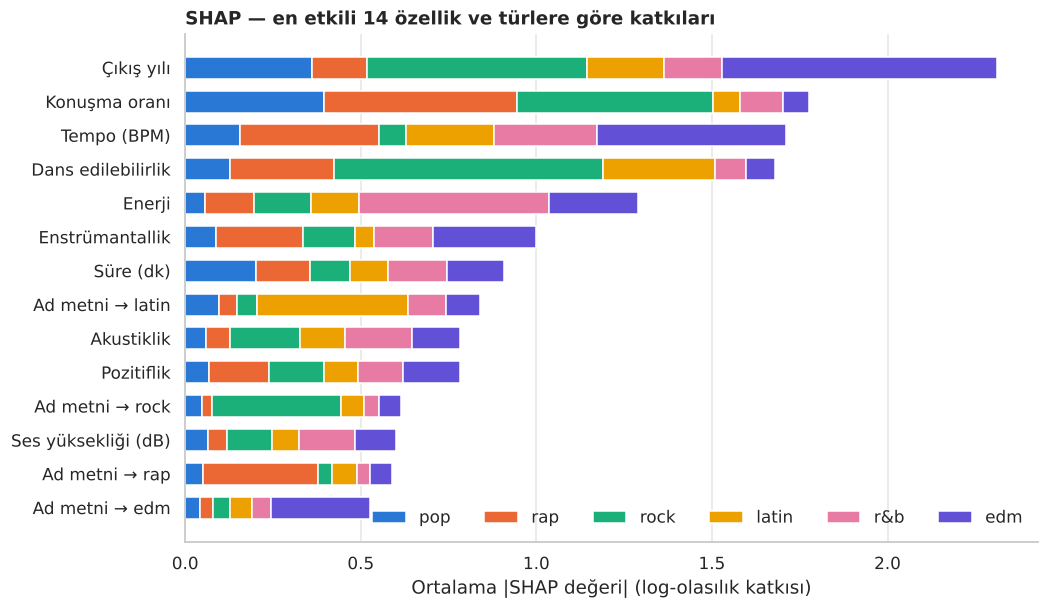

In [20]:
try:
    import shap
except ImportError:
    shap = None
    print("SHAP kurulu değil → pip install shap")

if shap is not None:
    shap_ornek = test[TUM].sample(1000, random_state=SEED)
    sv = shap.TreeExplainer(lgbm_son)(shap_ornek)
    siniflar = list(lgbm_son.classes_)

    onem = pd.DataFrame({t: np.abs(sv.values[:, :, siniflar.index(t)]).mean(0) for t in TURLER},
                        index=[TR[c] for c in shap_ornek.columns])
    onem = onem.loc[onem.sum(1).sort_values().index].tail(14)
    fig, ax = plt.subplots(figsize=(10, 6))
    sol = np.zeros(len(onem))
    for t in TURLER:
        ax.barh(onem.index, onem[t], left=sol, color=RENK[t], label=t, height=0.65, edgecolor="white", linewidth=1)
        sol += onem[t].values
    ax.legend(ncol=6, loc="lower right", frameon=False)
    ax.set_title("SHAP — en etkili 14 özellik ve türlere göre katkıları")
    ax.set_xlabel("Ortalama |SHAP değeri| (log-olasılık katkısı)"); ax.grid(axis="y", visible=False)
    plt.show()

Aşağıdaki **beeswarm** grafiklerinde her nokta bir şarkı. Sağa doğru olan noktalar modeli o türe *yaklaştırıyor*; renk özelliğin değerini gösteriyor (kırmızı = yüksek, mavi = düşük).

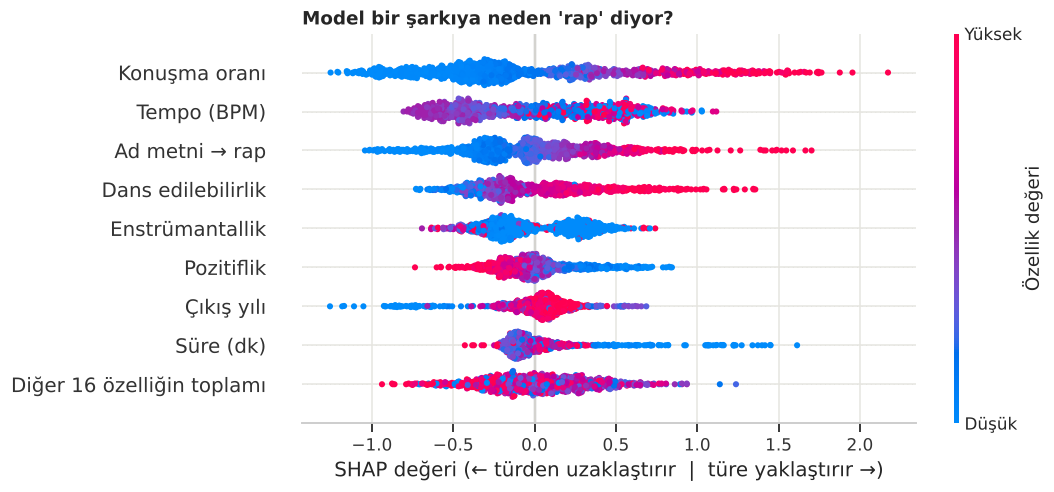

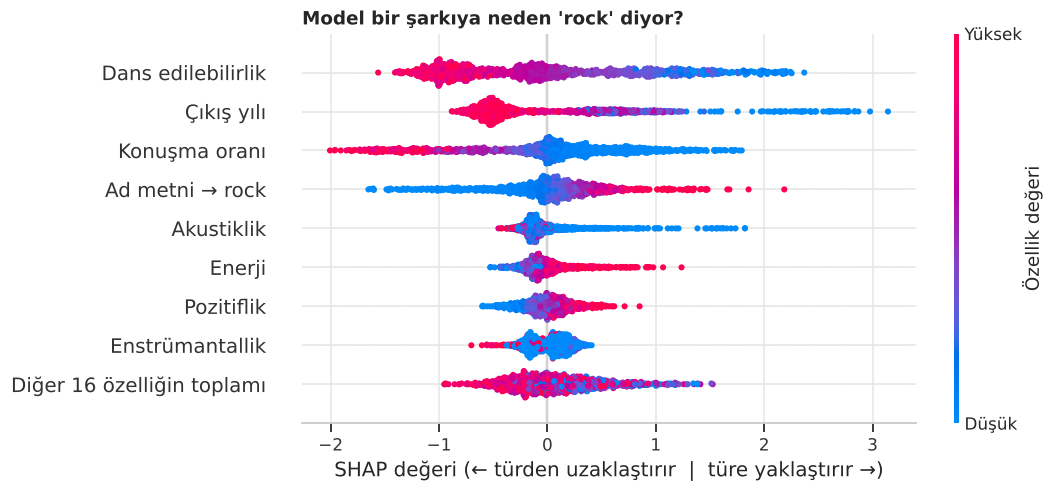

In [21]:
if shap is not None:
    for tur in ["rap", "rock"]:
        aciklama = sv[:, :, siniflar.index(tur)]
        aciklama.feature_names = [TR[c] for c in shap_ornek.columns]
        plt.figure()
        shap.plots.beeswarm(aciklama, max_display=9, show=False, plot_size=(9, 4.6))
        ana, renk_cubugu = plt.gcf().axes[0], plt.gcf().axes[-1]
        ana.set_xlabel("SHAP değeri (← türden uzaklaştırır  |  türe yaklaştırır →)")
        ana.set_yticklabels([e.get_text().replace("Sum of", "Diğer").replace("other features", "özelliğin toplamı")
                             for e in ana.get_yticklabels()])
        renk_cubugu.set_ylabel("Özellik değeri"); renk_cubugu.set_yticklabels(["Düşük", "Yüksek"])
        ana.set_title(f"Model bir şarkıya neden '{tur}' diyor?", loc="left", fontweight="bold")
        plt.show()

> 💡 **Rap** için en güçlü sinyaller yüksek konuşma oranı ve tempo; şarkı adı metin modeli üçüncü sırada geliyor. **Rock** için düşük dans edilebilirlik, eski çıkış yılı ve adındaki *remaster* izleri belirleyici. Genel sıralamada çıkış yılının en üstte olması büyük ölçüde **EDM**'den kaynaklanıyor: EDM kataloğu çok yeni olduğu için yıl bu türü ayırmada çok işe yarıyor.

### 9.8 Hata analizi: model en çok nerede yanıldı?
Modelin **en emin olduğu halde yanıldığı** şarkılar, verinin ya da tür etiketlerinin sınırlarını gösterir.

In [22]:
hatalar = test[["track_name", "track_artist", "playlist_genre", "playlist_subgenre"]].assign(tahmin=tahmin, guven=olas.max(1))
hatalar = hatalar[hatalar.playlist_genre != hatalar.tahmin]
(hatalar.nlargest(10, "guven")
 .rename(columns={"track_name": "Şarkı", "track_artist": "Sanatçı", "playlist_genre": "Gerçek tür",
                  "playlist_subgenre": "Alt tür", "tahmin": "Tahmin", "guven": "Güven"})
 .assign(Güven=lambda d: (d.Güven * 100).round(0).astype(int).astype(str) + "%").reset_index(drop=True))

,Şarkı,Sanatçı,Gerçek tür,Alt tür,Tahmin,Güven
0,Save Me,Djumpers,latin,latin pop,edm,98%
1,Without You - Remastered,Harry Nilsson,r&b,urban contemporary,rock,97%
2,Just Like Heaven,The Cure,pop,electropop,rock,97%
3,Karusell - Original Mix,Leroy Styles,latin,latin hip hop,edm,97%
4,Despacito - Remix,Luis Fonsi,pop,electropop,latin,96%
5,Callin' - Extended Mix,Lush & Simon,pop,dance pop,edm,94%
6,Latin Thugs - Explicit Album Version,Cypress Hill featuring Tego Calderon,latin,latin hip hop,rap,94%
7,Misty Blue,Dorothy Moore,r&b,urban contemporary,rock,94%
8,Hustler,Only1Tipy,pop,post-teen pop,rap,94%
9,I Got The... - 2006 Remaster,Labi Siffre,r&b,urban contemporary,rock,94%


> 💡 En emin hataların çoğu aslında **etiket sorunu** ya da yanıltıcı bir ipucu. Harry Nilsson'un *Without You - Remastered*'ı veride r&b, ama 70'ler sesi ve adındaki *Remastered* modeli rock'a götürüyor. The Cure'un *Just Like Heaven*'ı pop etiketli, oysa model haklı olarak rock diyor. *Despacito - Remix* pop listesinden geliyor; model ise latin diyor, ki açıkça haklı. Türler çalma listelerinden geldiği için etiketler gürültülü; bu da doğruluğun önündeki doğal bir tavan.

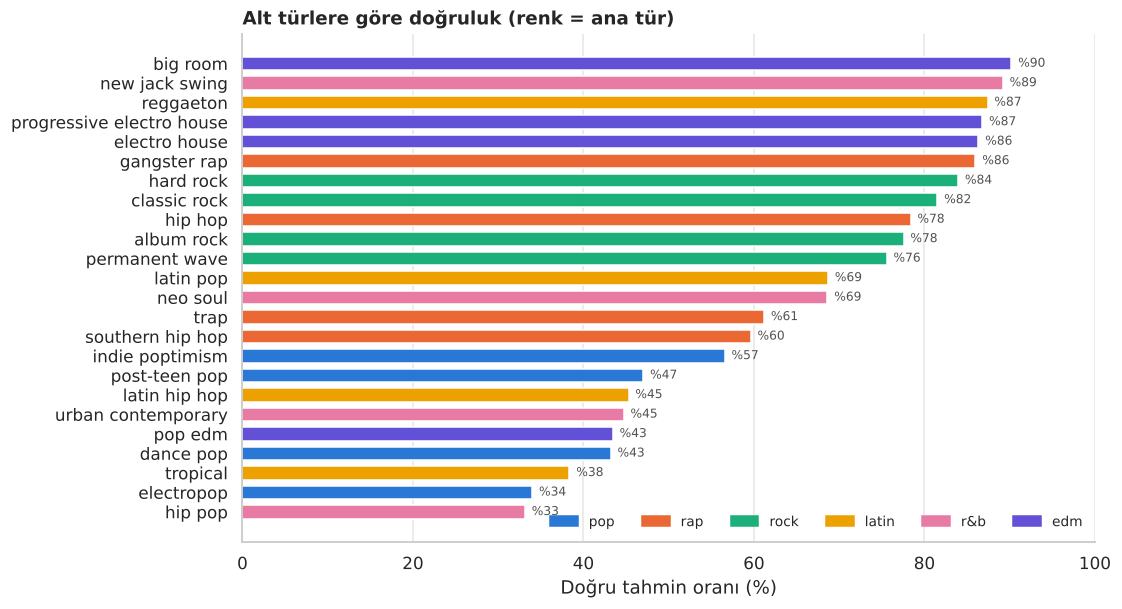

En kolay alt tür: big room (%90)  |  En zor: hip pop (%33)


In [23]:
from matplotlib.patches import Patch
alt = test.assign(dogru=(tahmin == y_test.values)).groupby("playlist_subgenre").dogru.mean().sort_values() * 100
renk_alt = tekil.drop_duplicates("playlist_subgenre").set_index("playlist_subgenre").playlist_genre.map(RENK)
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(alt.index, alt.values, color=renk_alt.reindex(alt.index), height=0.7)
for i, v in enumerate(alt.values):
    ax.text(v + 0.8, i, f"%{v:.0f}", va="center", fontsize=8, color=GRI)
ax.set_xlim(0, 100); ax.set_title("Alt türlere göre doğruluk (renk = ana tür)")
ax.set_xlabel("Doğru tahmin oranı (%)"); ax.grid(axis="y", visible=False)
ax.legend(handles=[Patch(color=RENK[t], label=t) for t in TURLER], ncol=6, loc="lower right", frameon=False, fontsize=9)
plt.show()
print(f"En kolay alt tür: {alt.index[-1]} (%{alt.iloc[-1]:.0f})  |  En zor: {alt.index[0]} (%{alt.iloc[0]:.0f})")

## 10. 🎵 Öneri sistemi

Her şarkıyı standartlaştırılmış ses özelliklerinden oluşan bir vektör olarak düşünüyoruz ve **kosinüs benzerliğine** göre en yakın komşularını buluyoruz. İsteğe bağlı olarak tür bilgisini de vektöre ekleyebiliyoruz.

In [24]:
ONERI_OZ = ["danceability", "energy", "loudness", "speechiness", "acousticness", "instrumentalness", "valence", "tempo"]
katalog = (sarkilar[sarkilar.track_popularity >= 40]                     # tanınır şarkılar
           .sort_values("track_popularity", ascending=False)
           .drop_duplicates(["track_name", "track_artist"]).reset_index(drop=True))  # aynı şarkının sürümlerini tekle
SES = StandardScaler().fit_transform(katalog[ONERI_OZ])
TUR = pd.get_dummies(katalog.playlist_genre).values * 1.5
VEKTORLER = {"ses": SES, "ses+tür": np.hstack([SES, TUR])}
print(f"Katalog: {len(katalog):,} şarkı")


def benzer_sarkilar(sarki, sanatci=None, n=8, mod="ses+tür"):
    # Verilen şarkıya en çok benzeyen n şarkı (isimde geçen ifadeyle arar)
    aday = katalog[katalog.track_name.str.lower().str.contains(sarki.lower(), regex=False)]
    if sanatci:
        aday = aday[aday.track_artist.str.lower().str.contains(sanatci.lower(), regex=False)]
    if aday.empty:
        print(f"'{sarki}' katalogda bulunamadı."); return None
    i = aday.track_popularity.idxmax()
    V = VEKTORLER[mod]
    nn = NearestNeighbors(n_neighbors=n + 20, metric="cosine").fit(V)
    uzaklik, komsu = nn.kneighbors(V[i:i + 1])
    sonuc = katalog.iloc[komsu[0]].assign(Benzerlik=1 - uzaklik[0])
    sonuc = sonuc[(sonuc.index != i) & (sonuc.track_artist != katalog.loc[i, "track_artist"])].head(n)
    print(f"🎧 {katalog.loc[i, 'track_name']} — {katalog.loc[i, 'track_artist']} "
          f"({katalog.loc[i, 'playlist_genre']} / {katalog.loc[i, 'playlist_subgenre']})")
    return (sonuc[["track_name", "track_artist", "playlist_subgenre", "Benzerlik"]]
            .rename(columns={"track_name": "Şarkı", "track_artist": "Sanatçı", "playlist_subgenre": "Alt tür"})
            .round(3).reset_index(drop=True))


benzer_sarkilar("Bohemian Rhapsody", "Queen")

Katalog: 14,710 şarkı
🎧 Bohemian Rhapsody - 2011 Mix — Queen (rock / album rock)


,Şarkı,Sanatçı,Alt tür,Benzerlik
0,Empty,The Cranberries,album rock,0.968
1,Torete,Moonstar88,classic rock,0.959
2,Jubilee Street,Nick Cave & The Bad Seeds,permanent wave,0.958
3,Sea of Love - 2006 Remaster,The Honeydrippers,album rock,0.953
4,Your Love,Alamid,classic rock,0.952
5,Maybe I’m Amazed - Remastered 2011,Paul McCartney,permanent wave,0.952
6,Fake Plastic Trees,Radiohead,permanent wave,0.947
7,Karma Police,Radiohead,permanent wave,0.942


In [25]:
benzer_sarkilar("Shape of You", "Ed Sheeran")

🎧 Shape of You — Ed Sheeran (pop / dance pop)


,Şarkı,Sanatçı,Alt tür,Benzerlik
0,in my miNd,Maty Noyes,indie poptimism,0.963
1,Me Quedo,Aitana,dance pop,0.958
2,Jesus In LA,Alec Benjamin,post-teen pop,0.942
3,The Weekend - Funk Wav Remix,SZA,electropop,0.924
4,Rockabye (feat. Sean Paul & Anne-Marie),Clean Bandit,electropop,0.922
5,Sunflower - Spider-Man: Into the Spider-Verse,Post Malone,post-teen pop,0.920
6,Soltera - Remix,Lunay,dance pop,0.918
7,Gravity,Ralph,indie poptimism,0.918


### Öneri sistemi ne kadar iyi?

Öneri sistemlerini değerlendirmek zordur, çünkü "doğru cevap" yok. Dolaylı bir ölçüt kullanıyoruz: **önerilen 10 şarkıdan kaçı, kaynak şarkıyla aynı alt türden?** (24 alt tür var; ör. *indie poptimism*, *hard rock*, *trap*). Rastgele seçilmiş 1.000 şarkı üzerinde ölçüp rastgele öneriyle karşılaştırıyoruz.

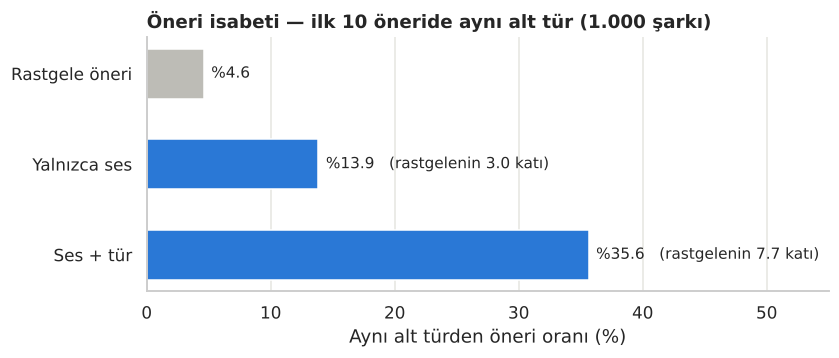

In [26]:
rng = np.random.default_rng(SEED)
kaynaklar = rng.choice(len(katalog), 1000, replace=False)
alt_tur = katalog.playlist_subgenre.values
isabet = {"Rastgele öneri": (katalog.playlist_subgenre.value_counts(normalize=True) ** 2).sum()}
for ad, V in VEKTORLER.items():
    _, komsu = NearestNeighbors(n_neighbors=11, metric="cosine").fit(V).kneighbors(V[kaynaklar])
    isabet[{"ses": "Yalnızca ses", "ses+tür": "Ses + tür"}[ad]] = np.mean(
        [(alt_tur[komsu[j, 1:]] == alt_tur[i]).mean() for j, i in enumerate(kaynaklar)])
isabet = pd.Series(isabet)

fig, ax = plt.subplots(figsize=(8, 3))
ax.barh(isabet.index[::-1], isabet.values[::-1] * 100, color=[RENK["pop"], RENK["pop"], "#bdbcb6"], height=0.55)
for i, v in enumerate(isabet.values[::-1]):
    kat = v / isabet.iloc[0]
    ax.text(v * 100 + 0.6, i, f"%{v*100:.1f}" + (f"   (rastgelenin {kat:.1f} katı)" if kat > 1.01 else ""),
            va="center", fontsize=10)
ax.set_xlim(0, 55); ax.set_xlabel("Aynı alt türden öneri oranı (%)")
ax.set_title("Öneri isabeti — ilk 10 öneride aynı alt tür (1.000 şarkı)"); ax.grid(axis="y", visible=False)
plt.show()

### Ruh haline göre çalma listesi

Hedef bir duygu (enerji + pozitiflik) veriyoruz; sistem bu noktaya en yakın şarkıları seçiyor ve **akıcı geçişler** için sıralıyor: her adımda tempo ve enerjisi bir öncekine en yakın şarkıya geçiyor (açgözlü en yakın komşu turu).

In [27]:
def calma_listesi(enerji, pozitiflik, n=12, tur=None, havuz=150):
    # Hedef duyguya yakın n şarkı seçer ve tempo/enerji geçişleri yumuşak olacak şekilde sıralar
    k = katalog if tur is None else katalog[katalog.playlist_genre == tur]
    uzaklik = np.hypot(k.energy - enerji, k.valence - pozitiflik)
    aday = k.assign(u=uzaklik).nsmallest(havuz, "u").drop_duplicates("track_artist").nsmallest(n, "u")
    nokta = np.c_[aday.tempo / 40, aday.energy * 3]          # tempo ve enerjiyi benzer ölçeğe getir
    sira, kalan = [int(np.argmin(aday.tempo.values))], set(range(len(aday)))
    kalan.remove(sira[0])
    while kalan:
        son = nokta[sira[-1]]
        sira.append(min(kalan, key=lambda j: np.linalg.norm(nokta[j] - son)))
        kalan.remove(sira[-1])
    return (aday.iloc[sira][["track_name", "track_artist", "playlist_genre", "tempo", "energy", "valence"]]
            .rename(columns={"track_name": "Şarkı", "track_artist": "Sanatçı", "playlist_genre": "Tür",
                             "tempo": "Tempo", "energy": "Enerji", "valence": "Pozitiflik"})
            .round(2).reset_index(drop=True))


print("🏋️ Spor listesi — yüksek enerji, yüksek pozitiflik")
calma_listesi(enerji=0.9, pozitiflik=0.75, n=10)

🏋️ Spor listesi — yüksek enerji, yüksek pozitiflik


,Şarkı,Sanatçı,Tür,Tempo,Enerji,Pozitiflik
0,Bouncin' Back (Bumpin' Me Against the Wall) (f...,Mystikal,rap,93.93,0.90,0.75
1,Aire,Leslie Grace,latin,100.01,0.90,0.74
2,Gyal You A Party Animal - Remix,Charly Black,latin,101.05,0.89,0.76
3,Just the Girl,The Click Five,pop,110.96,0.89,0.75
4,You Get What You Give,New Radicals,rock,113.97,0.90,0.74
5,All Star - Breathe Carolina Remix,Smash Mouth,pop,115.02,0.90,0.75
6,Forever Your Girl,Paula Abdul,r&b,119.97,0.89,0.75
7,Can't Stop Playing (Makes Me High) [feat. Ane ...,DR. KUCHO!,edm,125.00,0.90,0.75
8,Run the World (Girls),Beyoncé,pop,127.09,0.90,0.76
9,Se Prendió,Agus Padilla,latin,177.98,0.90,0.76


In [28]:
print("🌧️ Yağmurlu akşam — düşük enerji, düşük pozitiflik")
calma_listesi(enerji=0.3, pozitiflik=0.2, n=10)

🌧️ Yağmurlu akşam — düşük enerji, düşük pozitiflik


,Şarkı,Sanatçı,Tür,Tempo,Enerji,Pozitiflik
0,"Hey, Ma",Bon Iver,r&b,72.14,0.28,0.21
1,Takeoff,High John,rap,83.85,0.31,0.20
2,With U,SwuM,rap,90.03,0.31,0.18
3,jasmine (demo),Jai Paul,pop,89.53,0.29,0.20
4,Doing Alright - Remastered 2011,Queen,rock,93.01,0.29,0.19
5,Fast Car,Tracy Chapman,pop,103.95,0.29,0.19
6,Watch Me Dance,Tom Misch,pop,118.00,0.29,0.19
7,That's What Friends Are For,Dionne Warwick,rock,120.12,0.29,0.20
8,This Way (Khalid x H.E.R.),Khalid,r&b,124.61,0.28,0.19
9,so sad,Mike Vallas,pop,147.31,0.31,0.20


> 🔁 Kendin dene: `benzer_sarkilar("şarkı adı", "sanatçı")` ya da `calma_listesi(enerji=0.6, pozitiflik=0.8, tur="latin")`

## 11. Sonuçlar

| # | Konu | Bulgu |
|---|---|---|
| 1 | Türlerin ses imzası | Türleri en iyi ayıran özellikler **konuşma oranı** (ε² = 0,20) ve **dans edilebilirlik** (ε² = 0,19); *canlı kayıt* neredeyse hiç fark yaratmıyor (ε² = 0,005). |
| 2 | Duygular | **Latin** şarkıların %65'i "mutlu" bölgede; **EDM** yüksek enerjisine rağmen %65 oranında "gergin". Hüzünlü şarkıların en yüksek payı **r&b**'de (%20). |
| 3 | Zaman | Şarkılar **kısalıyor** (1990'larda medyan 4,4 dk → 2010'larda 3,5 dk), **yükseliyor** (−9,3 → −5,9 dB) ve **hüzünleniyor**: 2010'larda pozitiflik 0,62'den 0,47'ye düştü; hüzünlü + gergin şarkıların payı %32'den **%55'e** çıktı. |
| 4 | Popülerlik | Ses özellikleri popülerliğin yalnızca **%7**'sini açıklıyor; yıl ve tür ile %13, **sanatçı bilgisiyle %26**. |
| 5 | Tür tahmini | Optuna ile ayarlı LightGBM, yalnızca ses özellikleriyle **%62,2**. Şarkı adından çıkarılan ipuçları ve TF-IDF metin modeliyle (stacking) **%65,8 doğruluk, 0,653 macro F1, %83,9 ilk 2 doğruluk**. Sanatçı bilgisiyle ayrı senaryoda **%77,9**. |
| 6 | Optimizasyon dersi | Hiperparametre ayarı ses özellikleriyle tavanı aşamadı; kazanç **yeni bilgiden** geldi. Ensemble bu veride ek katkı sağlamadı. |
| 7 | Genelleme | Sanatçıya göre bölmede (GroupKFold) doğruluk yalnızca **1,5 puan** düşüyor: model sanatçıları ezberlemiyor, gerçekten sesten öğreniyor. |
| 8 | Açıklanabilirlik ve hatalar | SHAP, modelin istatistiksel testlerle tutarlı düşündüğünü gösteriyor. En emin hataların çoğu **etiket gürültüsü** (ör. The Cure "pop" etiketli). |
| 9 | Öneri sistemi | Yalnızca ses özellikleriyle öneriler rastgeleye göre **3 kat**, tür bilgisiyle **7,7 kat** daha sık aynı alt türden geliyor. |

**Genel çıkarım:** Ses özellikleri bir şarkının *türünü* ve *duygusunu* makul ölçüde ele veriyor ama *başarısını* açıklamıyor. Model doğruluğunu artırmanın yolu daha karmaşık algoritmalar değil, **farklı türde bilgi** eklemek oldu. Kalan hataların önemli kısmı ise türlerin kendisinin bulanık olmasından ve etiketlerin çalma listesi küratörlerinin yorumuna dayanmasından kaynaklanıyor.

### Geliştirme fikirleri
- Şarkı sözlerini ekleyip NLP ile hem tür tahminini hem duygu analizini güçlendirmek
- 24 alt türü hiyerarşik bir modelle tahmin etmek (önce ana tür, sonra alt tür)
- Öneri sistemini işbirlikçi filtreleme (kullanıcı dinleme verisi) ile birleştirmek